# Delhi Pollution all stations 2026
#### Data from the public [OpenAQ archive](https://openaq-data-archive.s3.amazonaws.com) (CPCB / DPCC / IMD stations plus the US Embassy, no API key needed)

Diwali 2026: **8 November**. The 2015 data.gov.in dataset has no 2026 edition, so hourly station readings are
pulled from OpenAQ and averaged to daily values like the 2015 CPCB data. The archive lags a few days —
re-run this notebook to fill in Diwali and the days after.

In [1]:
import os
from datetime import date

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
%matplotlib inline

from openaq_delhi import get_hourly, daily_means

DIWALI = pd.Timestamp("2026-11-08")
START, END = date(2026, 9, 1), date(2026, 11, 30)
GRAPH_DIR = "graphs_2026"
os.makedirs(GRAPH_DIR, exist_ok=True)

LABELS = {"pm25": "PM2.5 (µg/m³)", "pm10": "PM10 (µg/m³)", "no2": "NO2 (µg/m³)"}
# 24-h National Ambient Air Quality Standards
NAAQS = {"pm25": 60, "pm10": 100, "no2": 80}

In [2]:
hourly = get_hourly(START, min(END, date.today()))
all_record_df = daily_means(hourly)
print("data up to", hourly["datetime"].max())

data up to 2026-11-05 00:00:00


# Distinct locations

In [3]:
all_record_df["station"].unique()

<StringArray>
[      'Anand Vihar',         'Aya Nagar', 'CRRI Mathura Road',
               'DTU',  'IGI Airport (T3)',               'ITO',
        'Lodhi Road',       'NSIT Dwarka',  'North Campus, DU',
      'Punjabi Bagh',              'Pusa',         'R K Puram',
          'Shadipur',          'Sirifort',        'US Embassy']
Length: 15, dtype: str

In [4]:
def _decorate(ax, pollutant, title):
    ax.axvline(DIWALI, linewidth=1, color="red", label="Diwali (8 Nov)")
    ax.axhline(NAAQS[pollutant], linewidth=1, color="grey", linestyle="--", label="24-h standard")
    ax.set_xlim(pd.Timestamp(START), max(DIWALI + pd.Timedelta(days=10), all_record_df["date"].max()))
    ax.set_ylabel(LABELS[pollutant])
    ax.set_xlabel(title)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.grid(alpha=0.3)


def plot_all_data(df, pollutant):
    fig, ax = plt.subplots(figsize=(20, 10))
    for station, sdf in df.groupby("station"):
        sdf = sdf.dropna(subset=[pollutant])
        ax.plot(sdf["date"], sdf[pollutant], "*-", linewidth=2, label=station)
    _decorate(ax, pollutant, "Date (all Delhi stations, 2026)")
    ax.legend(ncol=2, fontsize=9)
    fig.savefig(f"{GRAPH_DIR}/all_stations_{pollutant}.png", dpi=100, bbox_inches="tight")

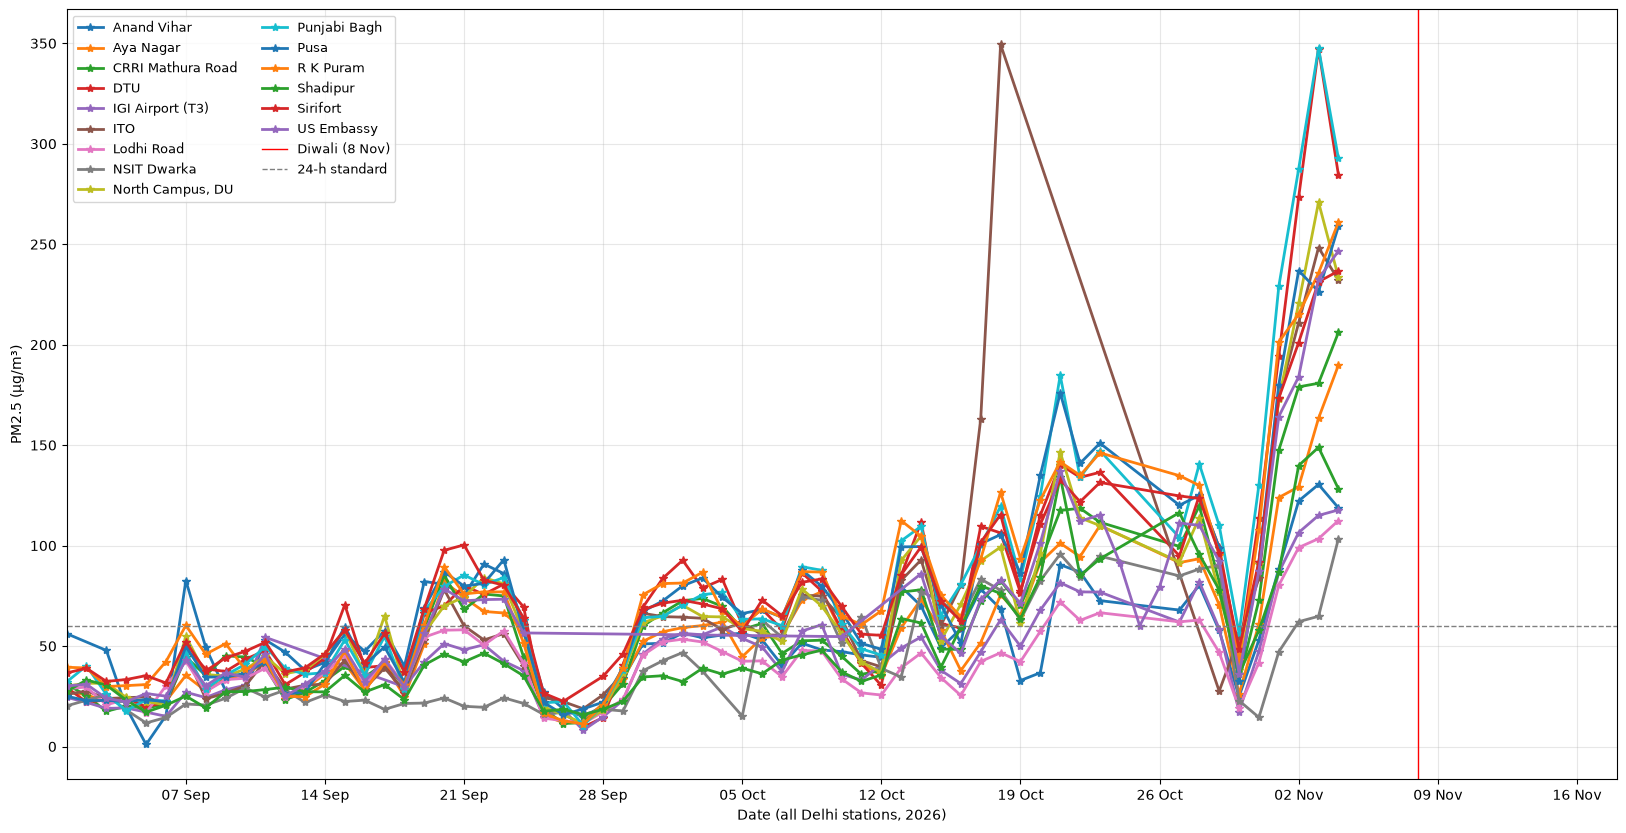

In [5]:
plot_all_data(all_record_df, "pm25")

In [6]:
def plot_all_data_different_plot(df, pollutant):
    for station, sdf in df.groupby("station"):
        sdf = sdf.dropna(subset=[pollutant])
        if sdf.empty:  # e.g. US Embassy measures PM2.5 only
            continue
        fig, ax = plt.subplots(figsize=(20, 10))
        ax.plot(sdf["date"], sdf[pollutant], "*-", linewidth=2)
        _decorate(ax, pollutant, f"Date in station {station}")
        slug = station.lower().replace(",", "").replace("(", "").replace(")", "").replace(" ", "_")
        fig.savefig(f"{GRAPH_DIR}/{slug}_{pollutant}.png", dpi=100, bbox_inches="tight")

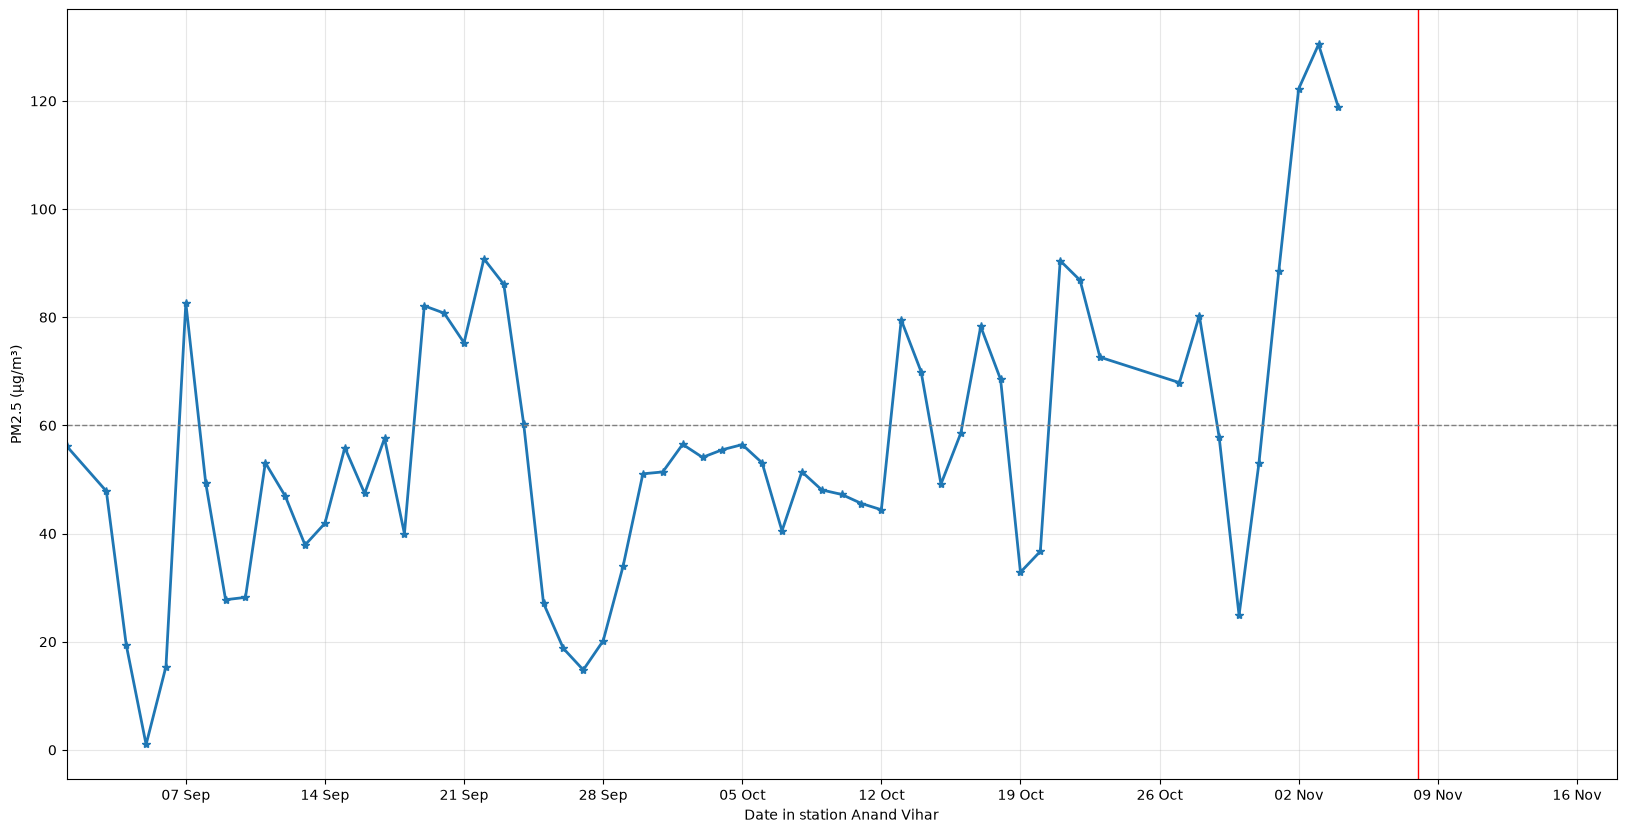

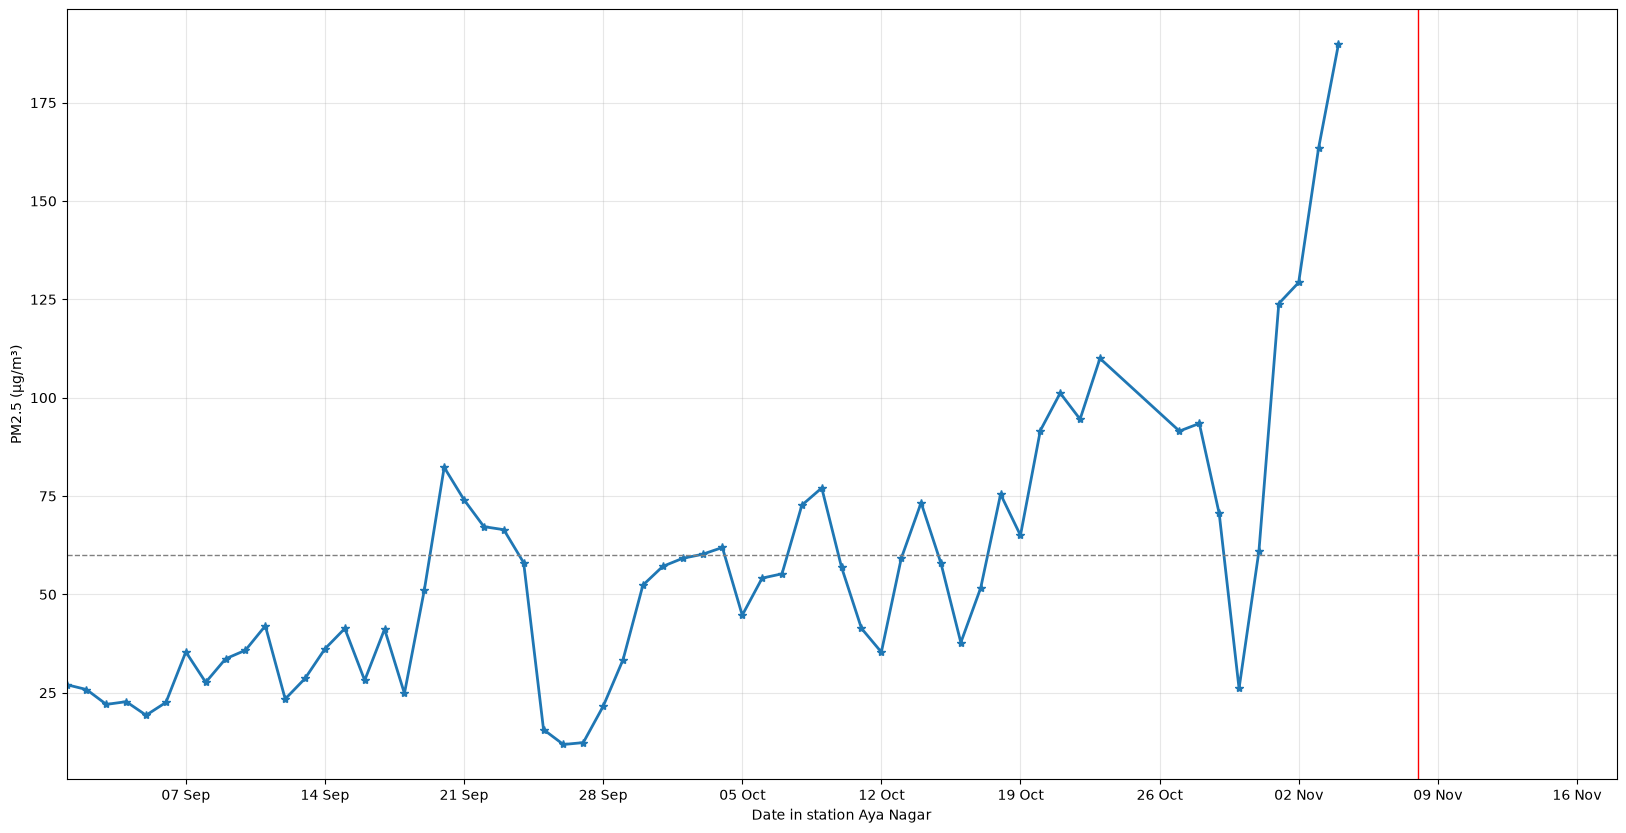

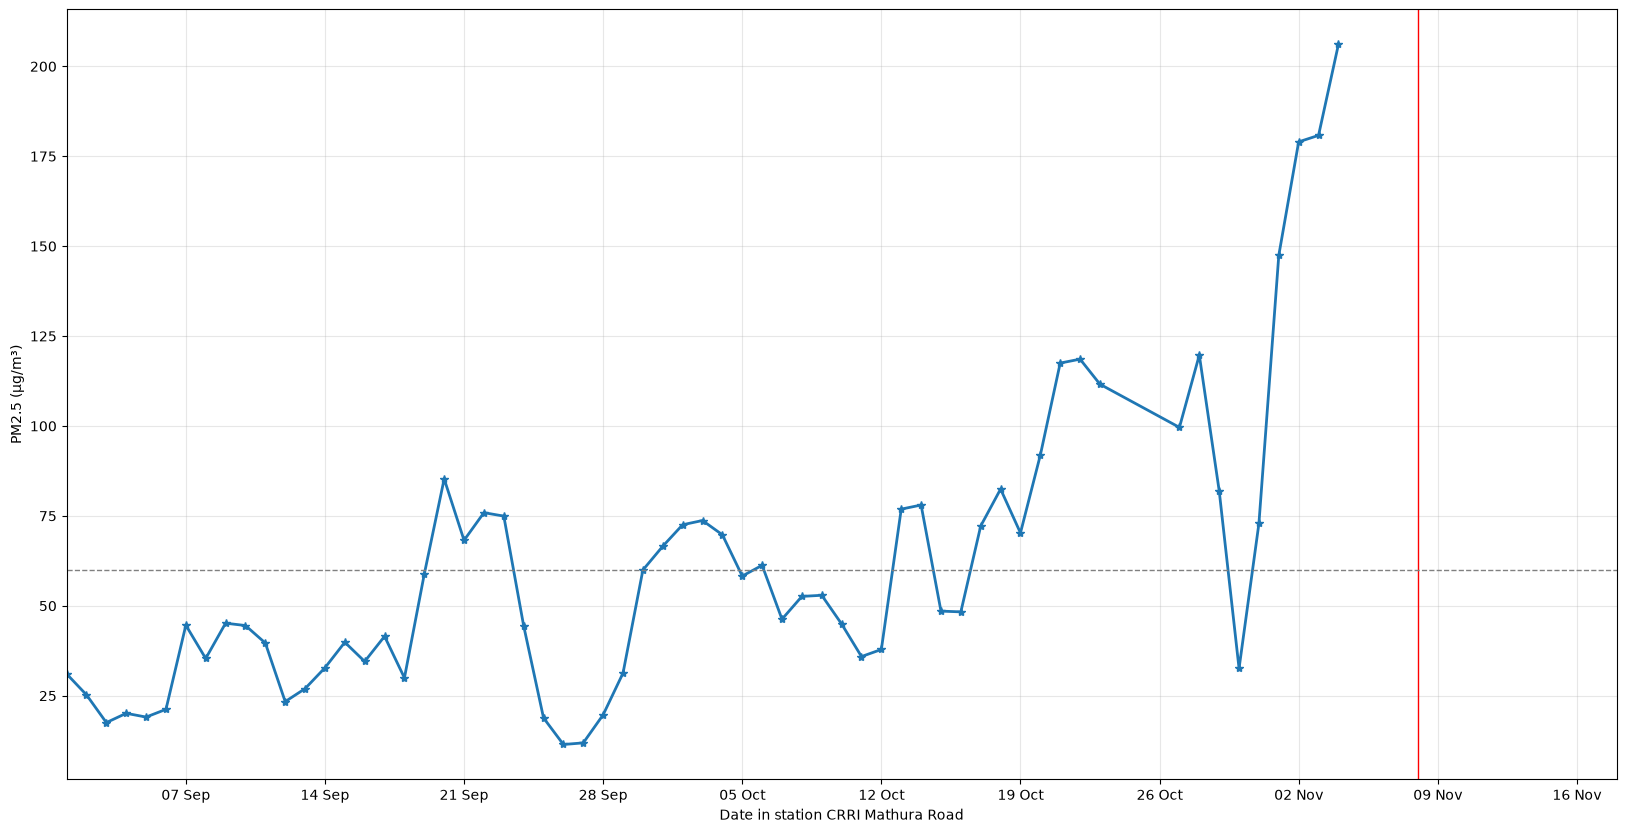

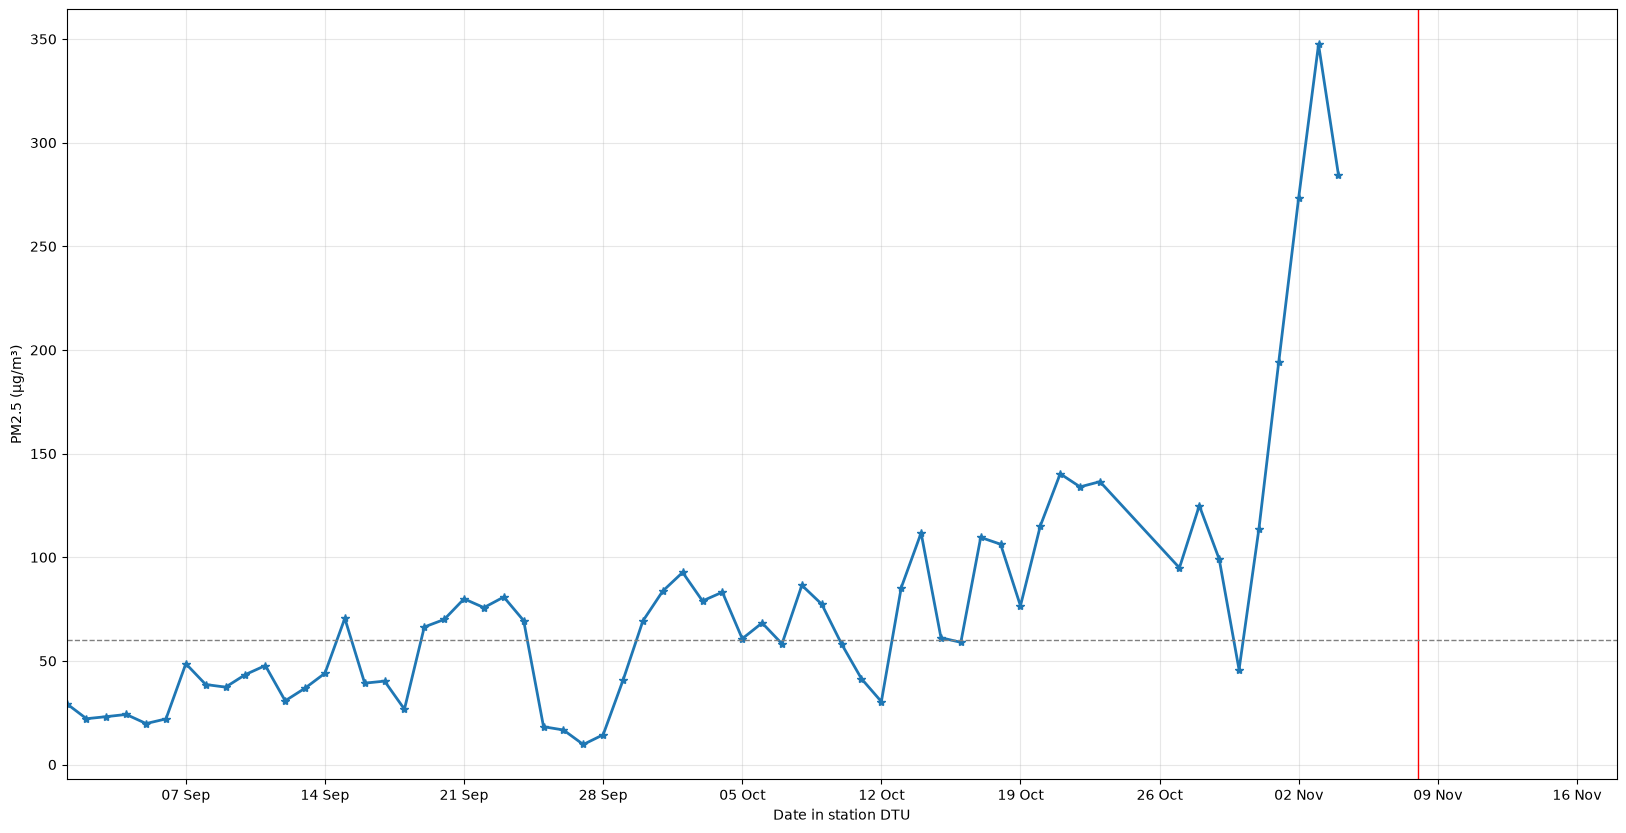

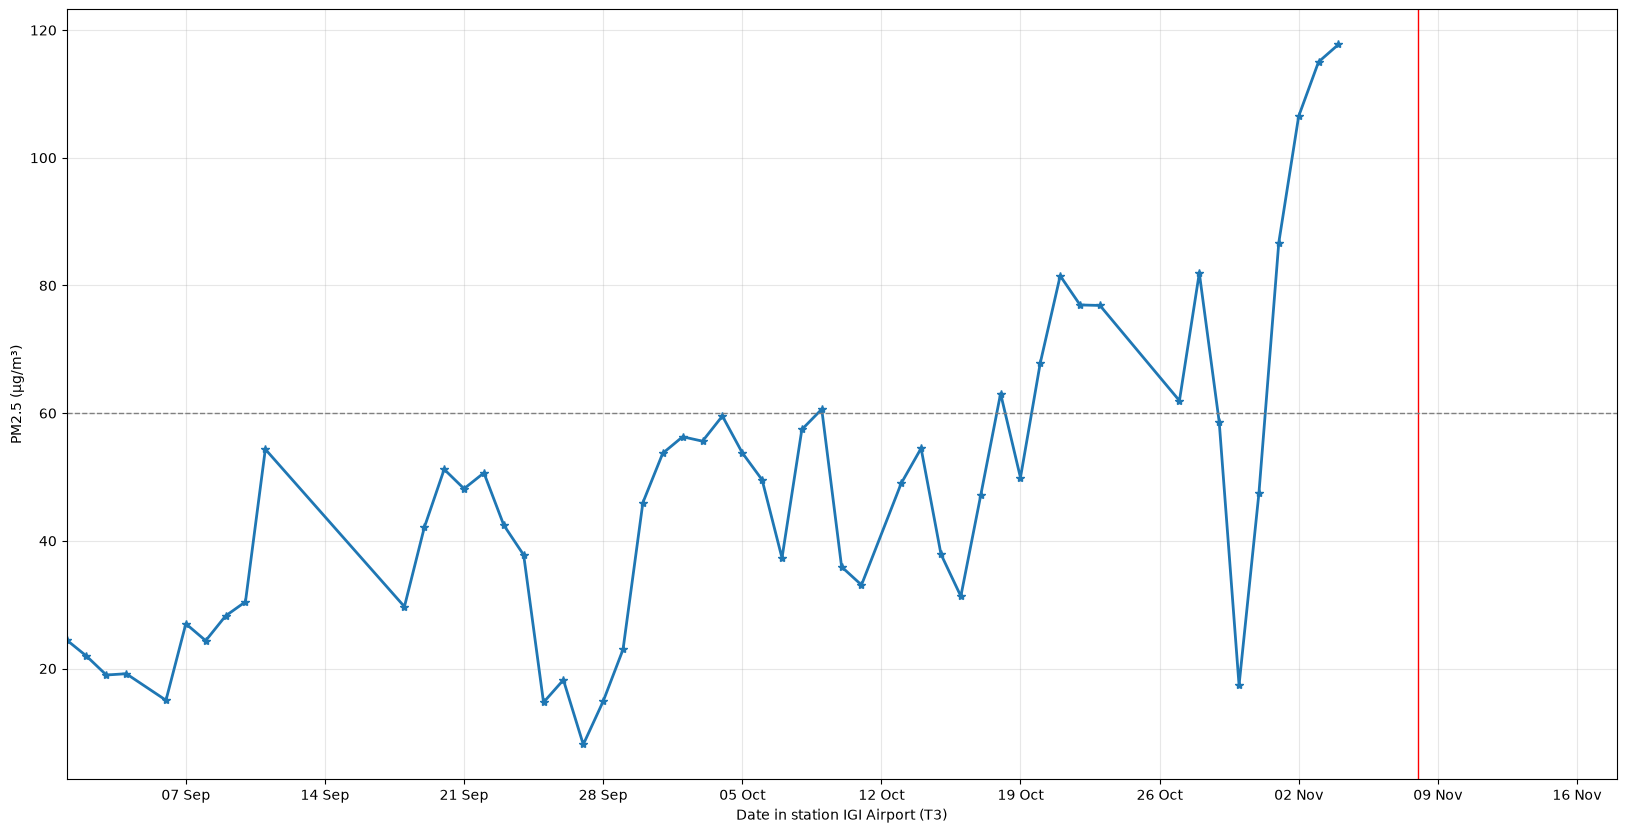

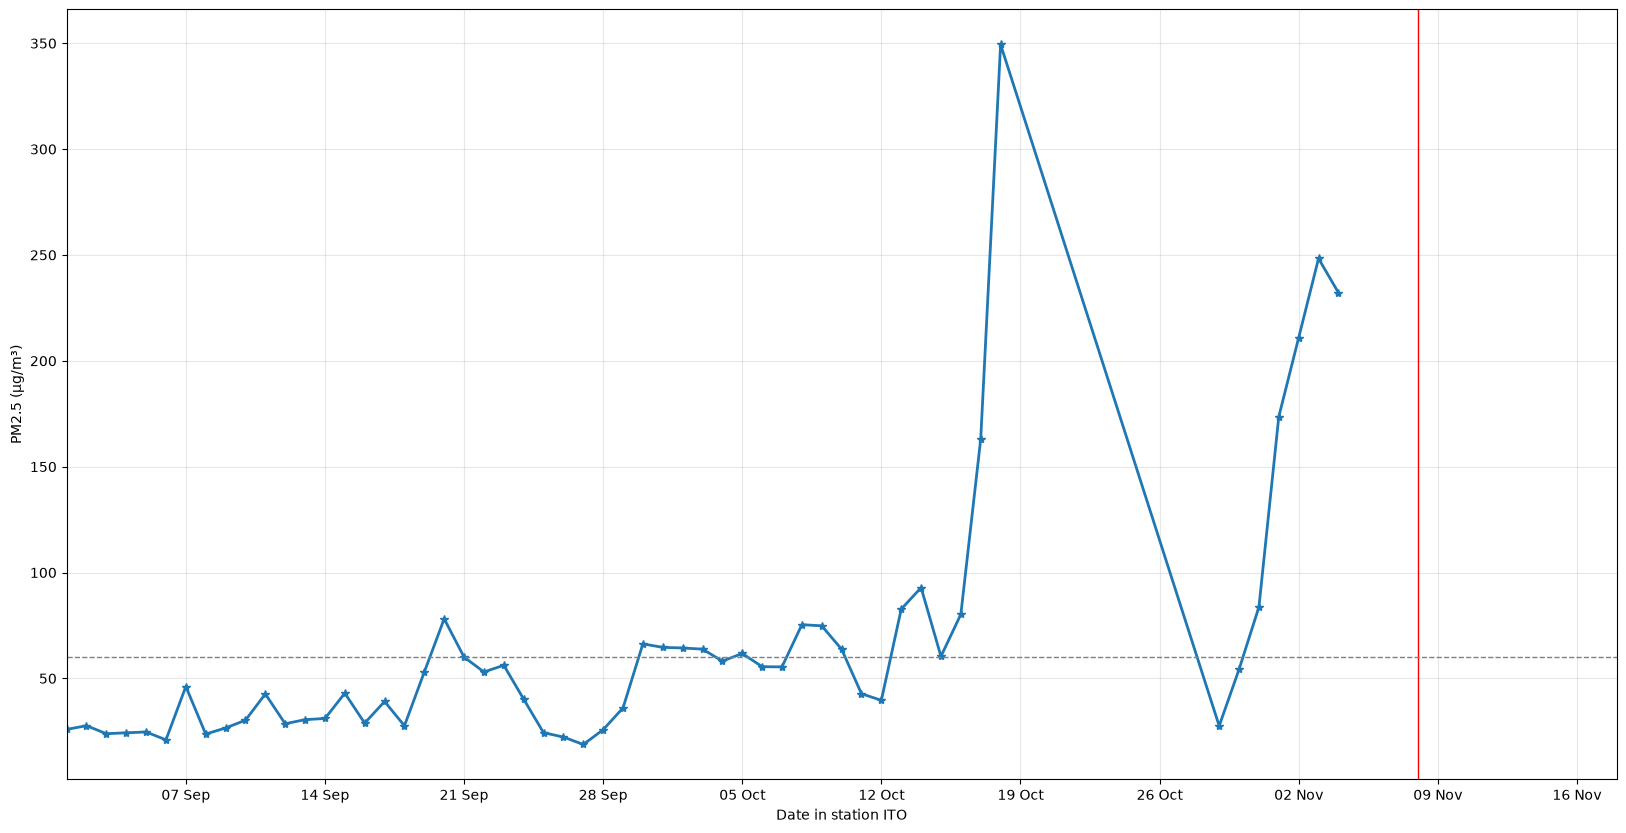

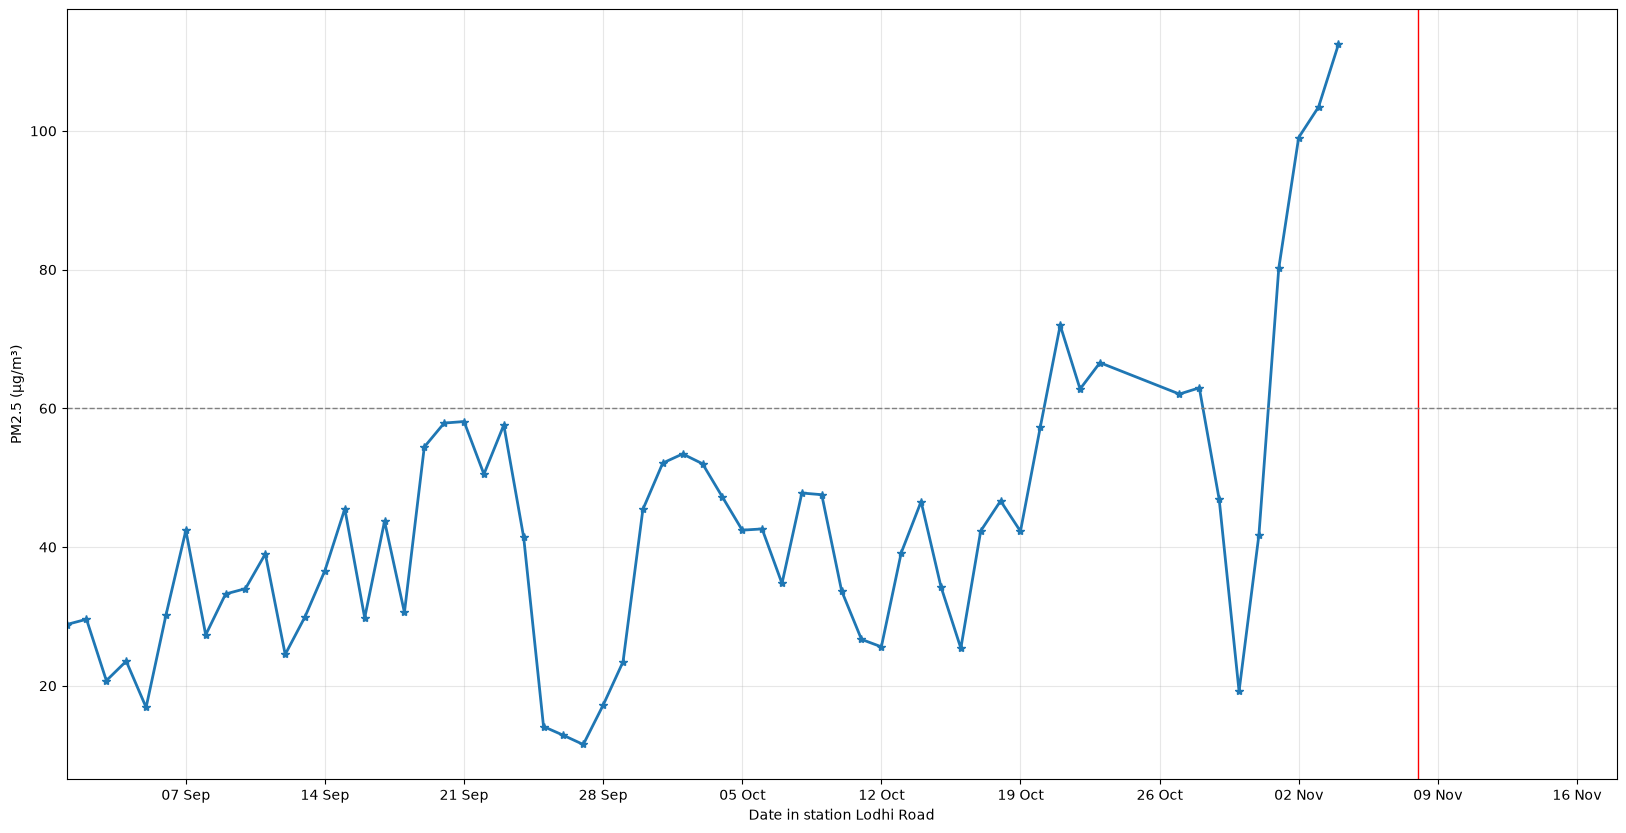

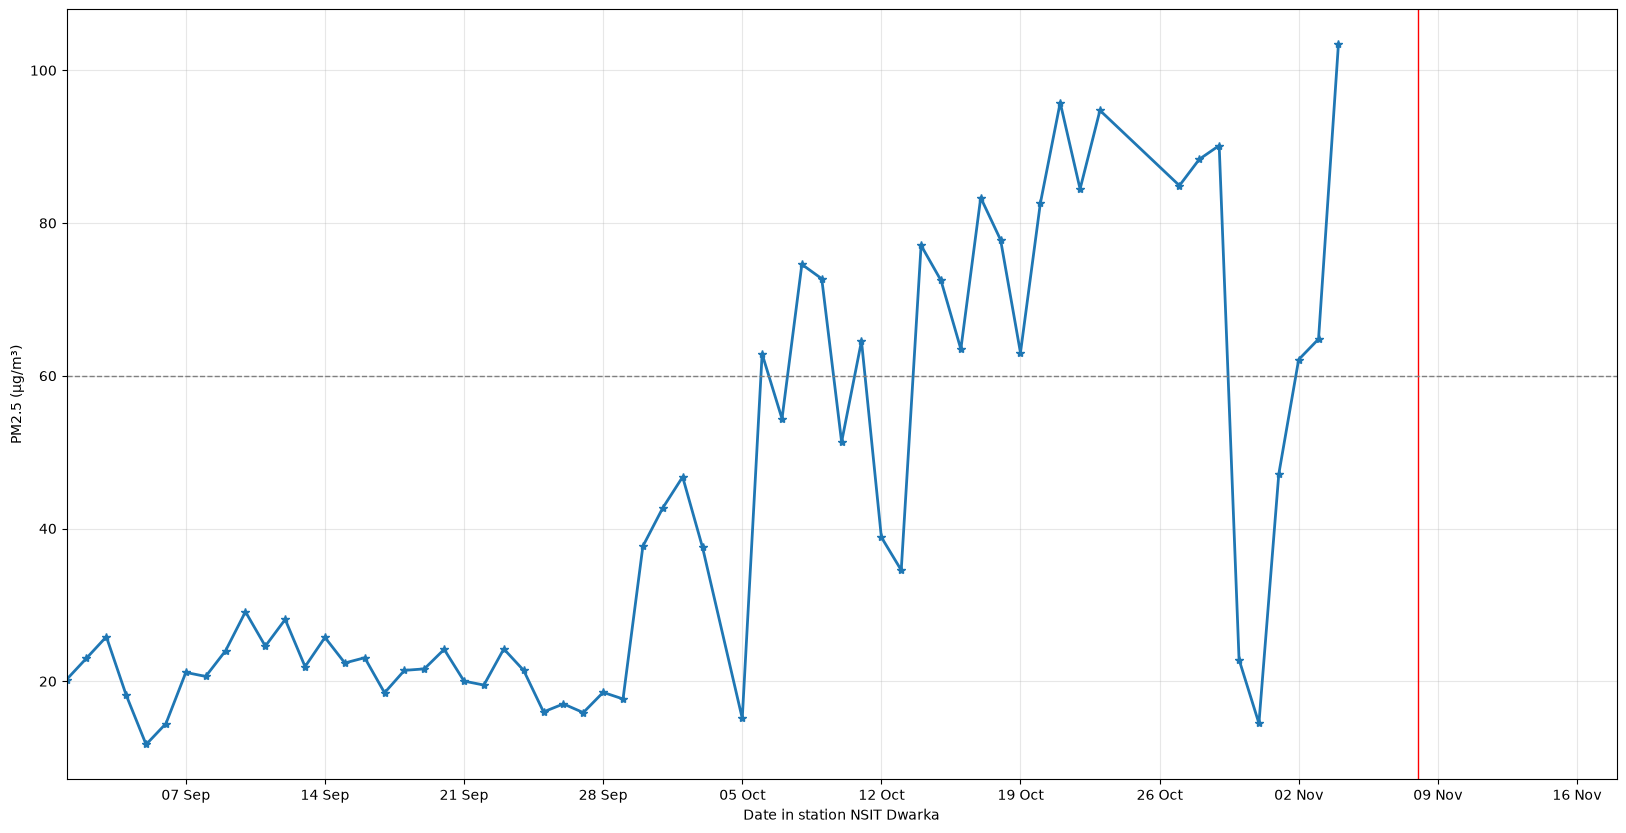

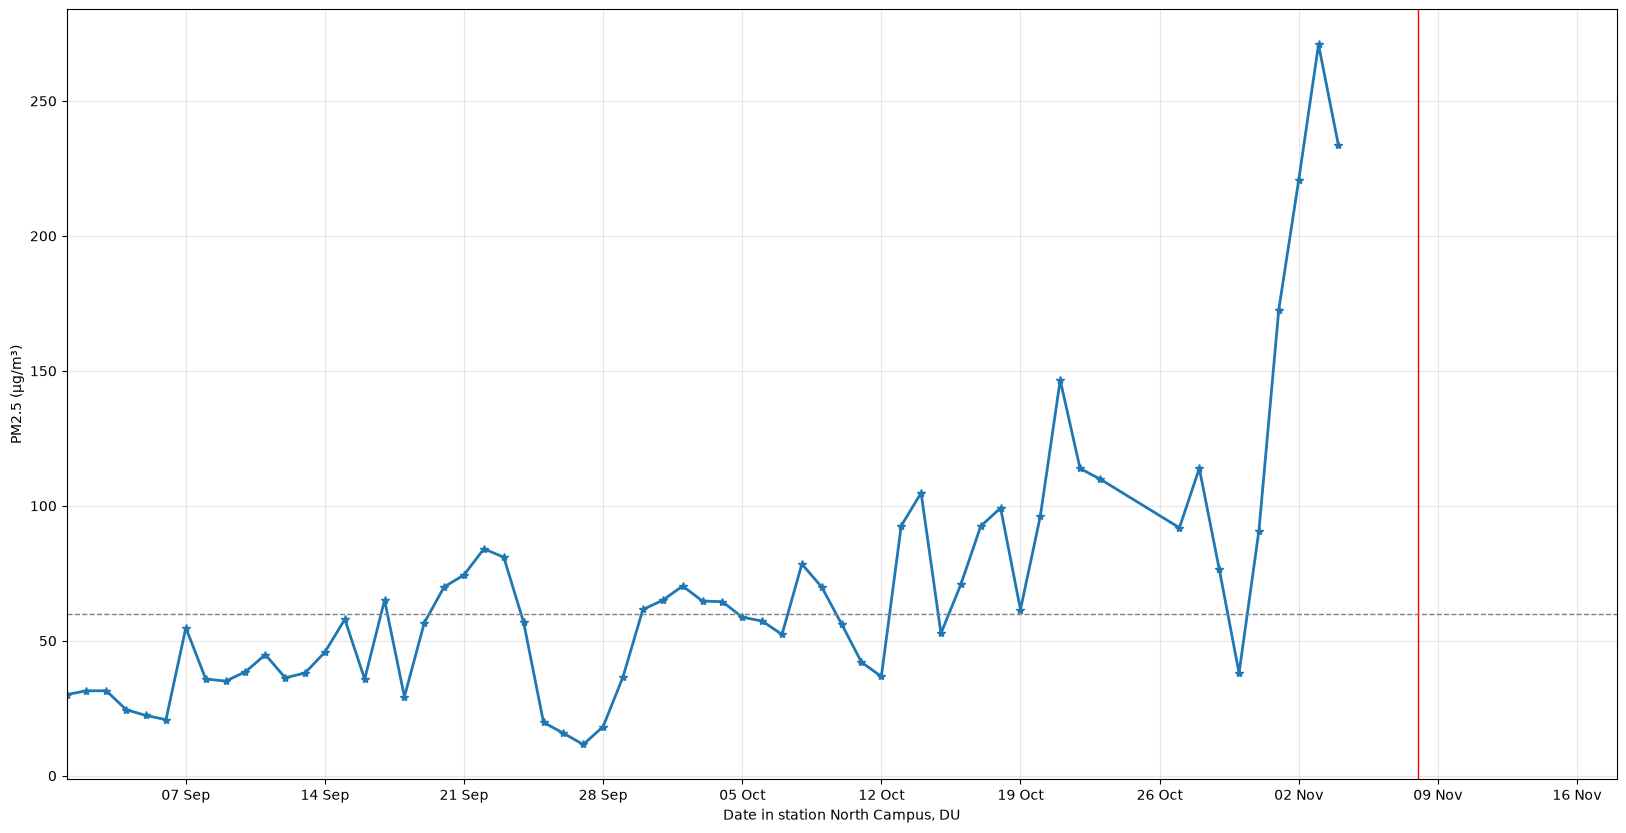

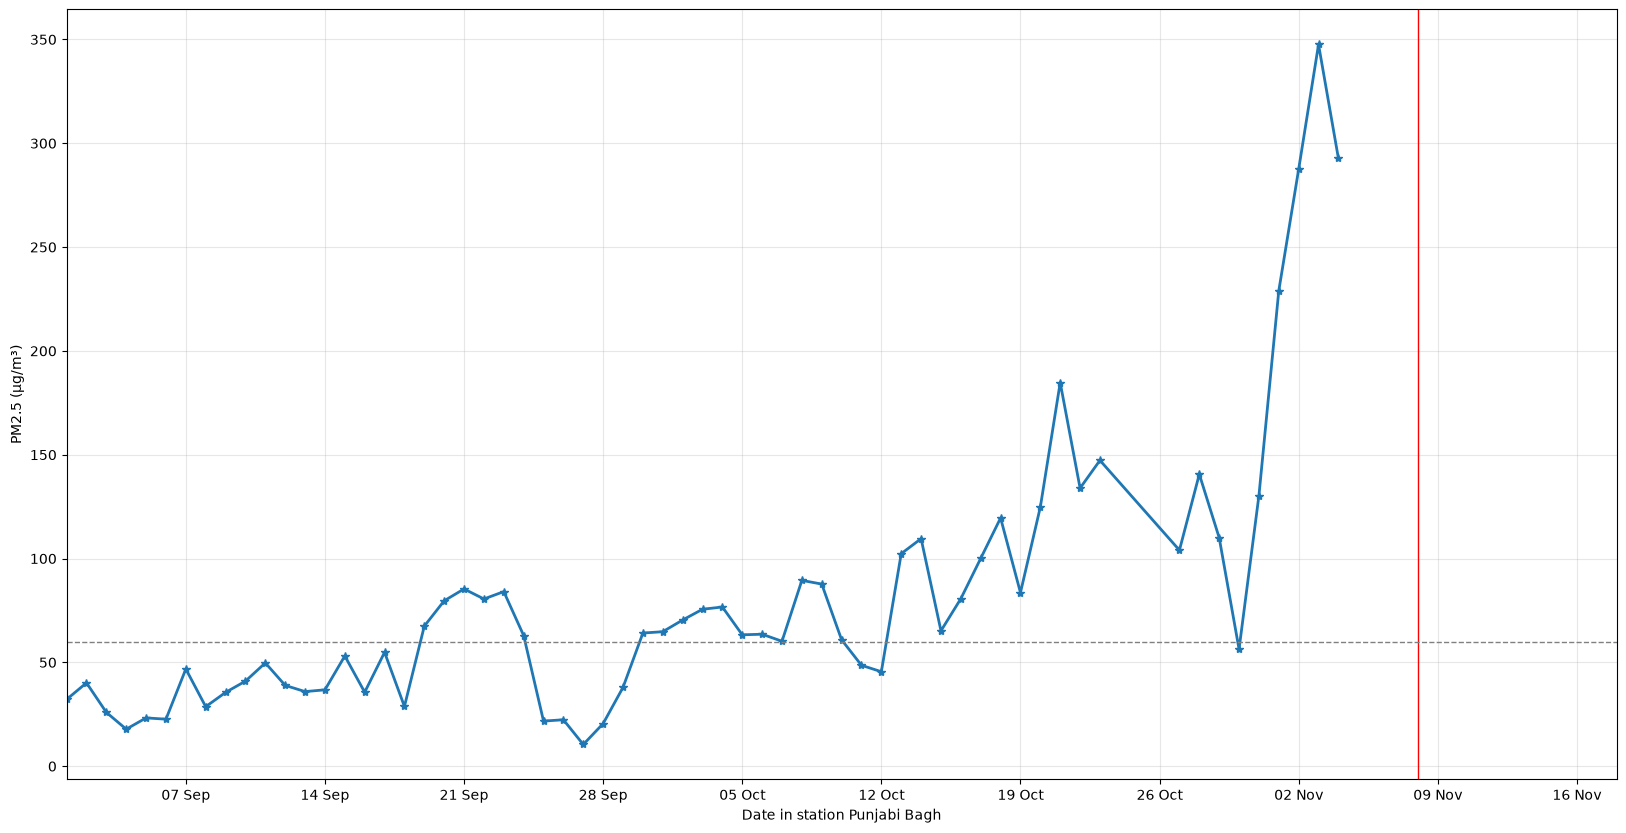

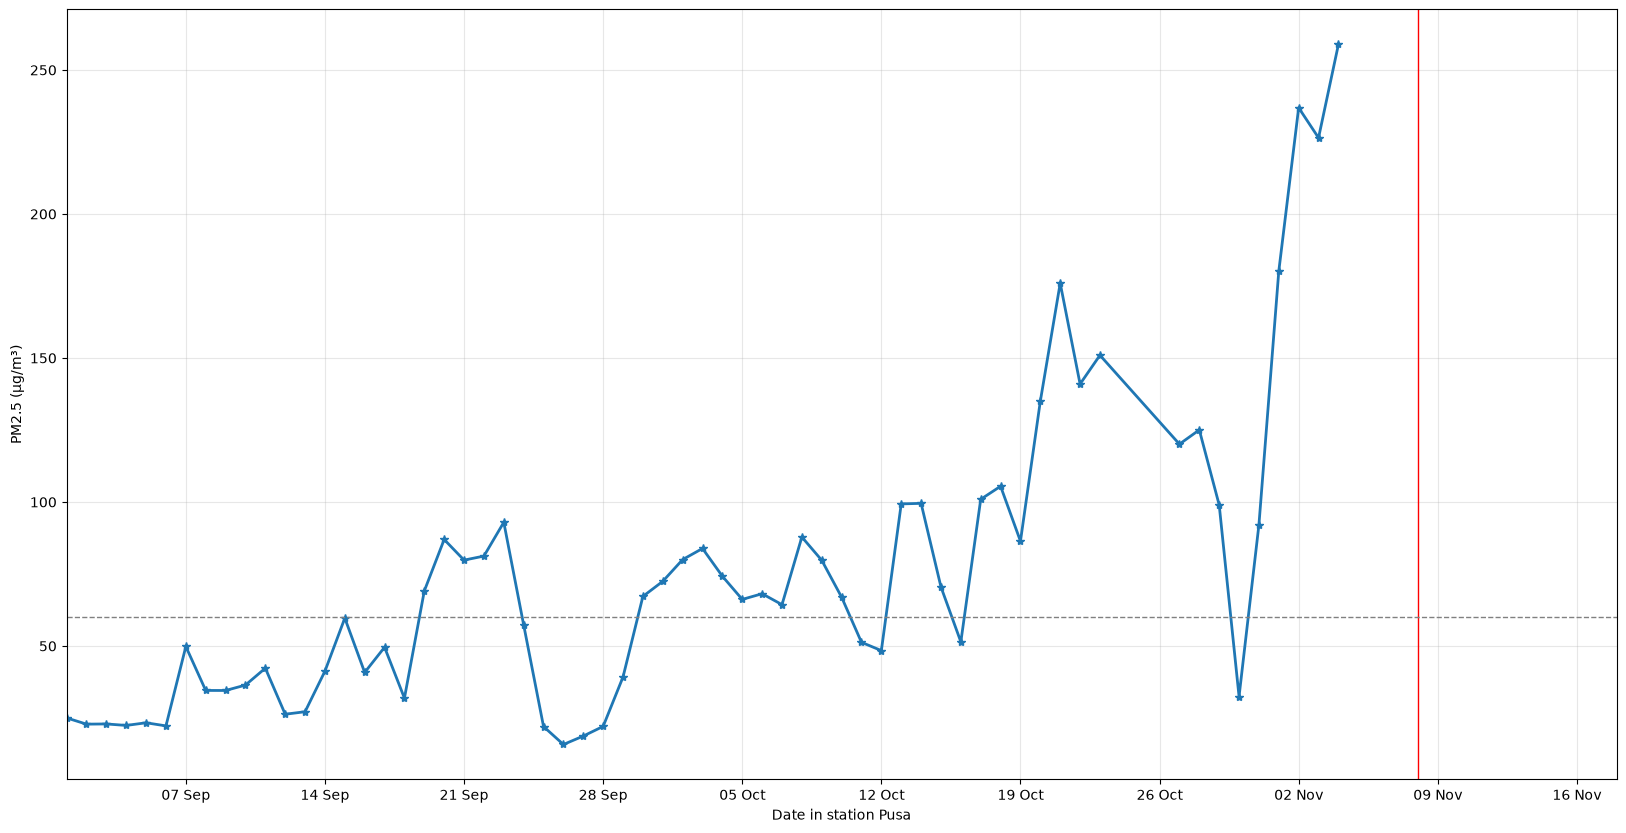

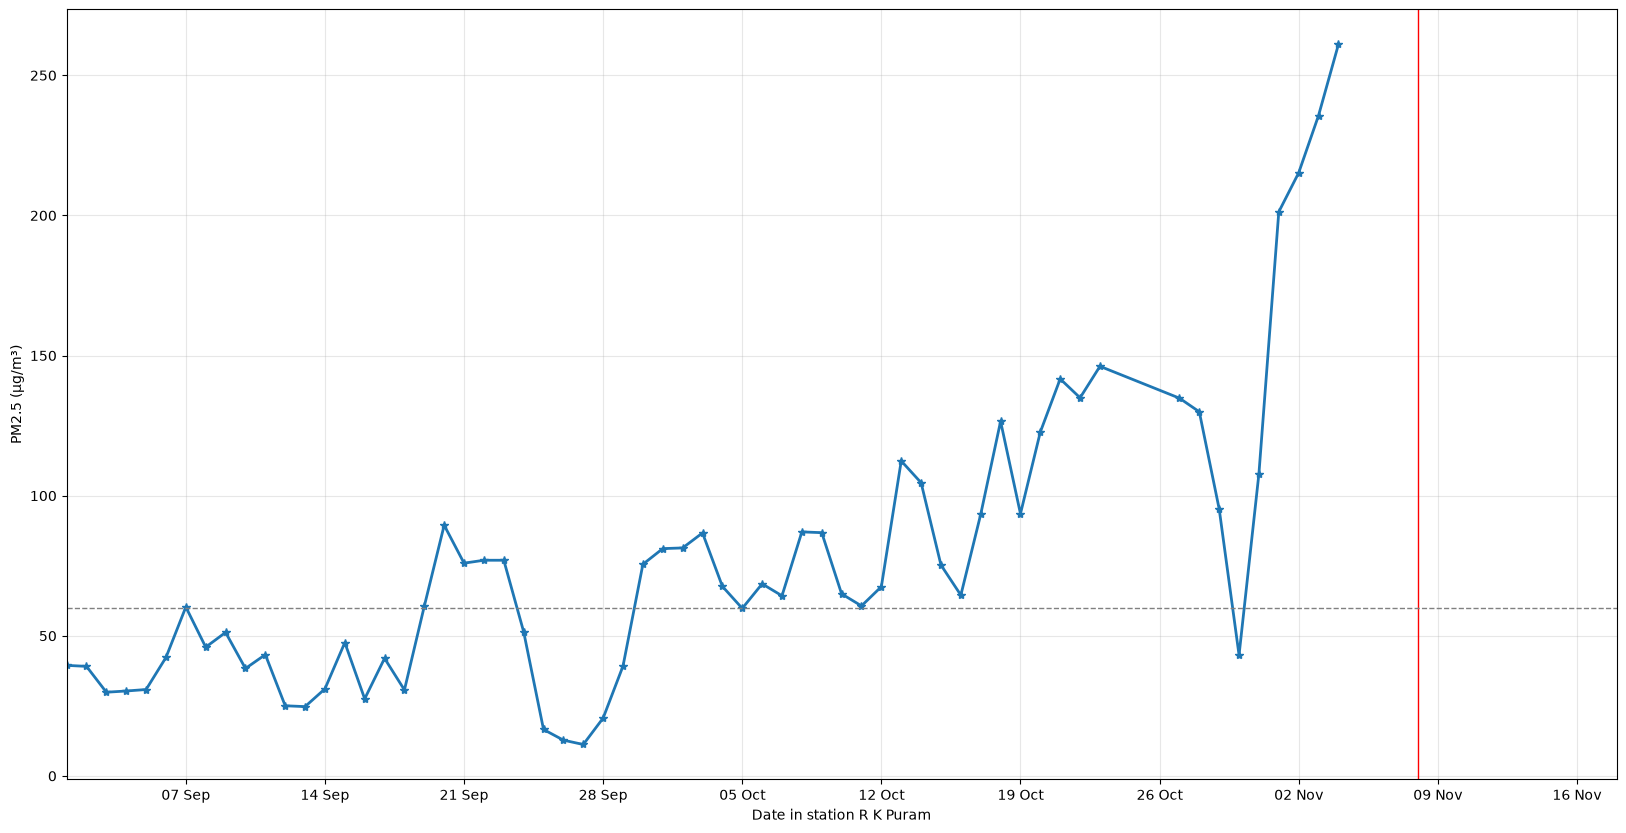

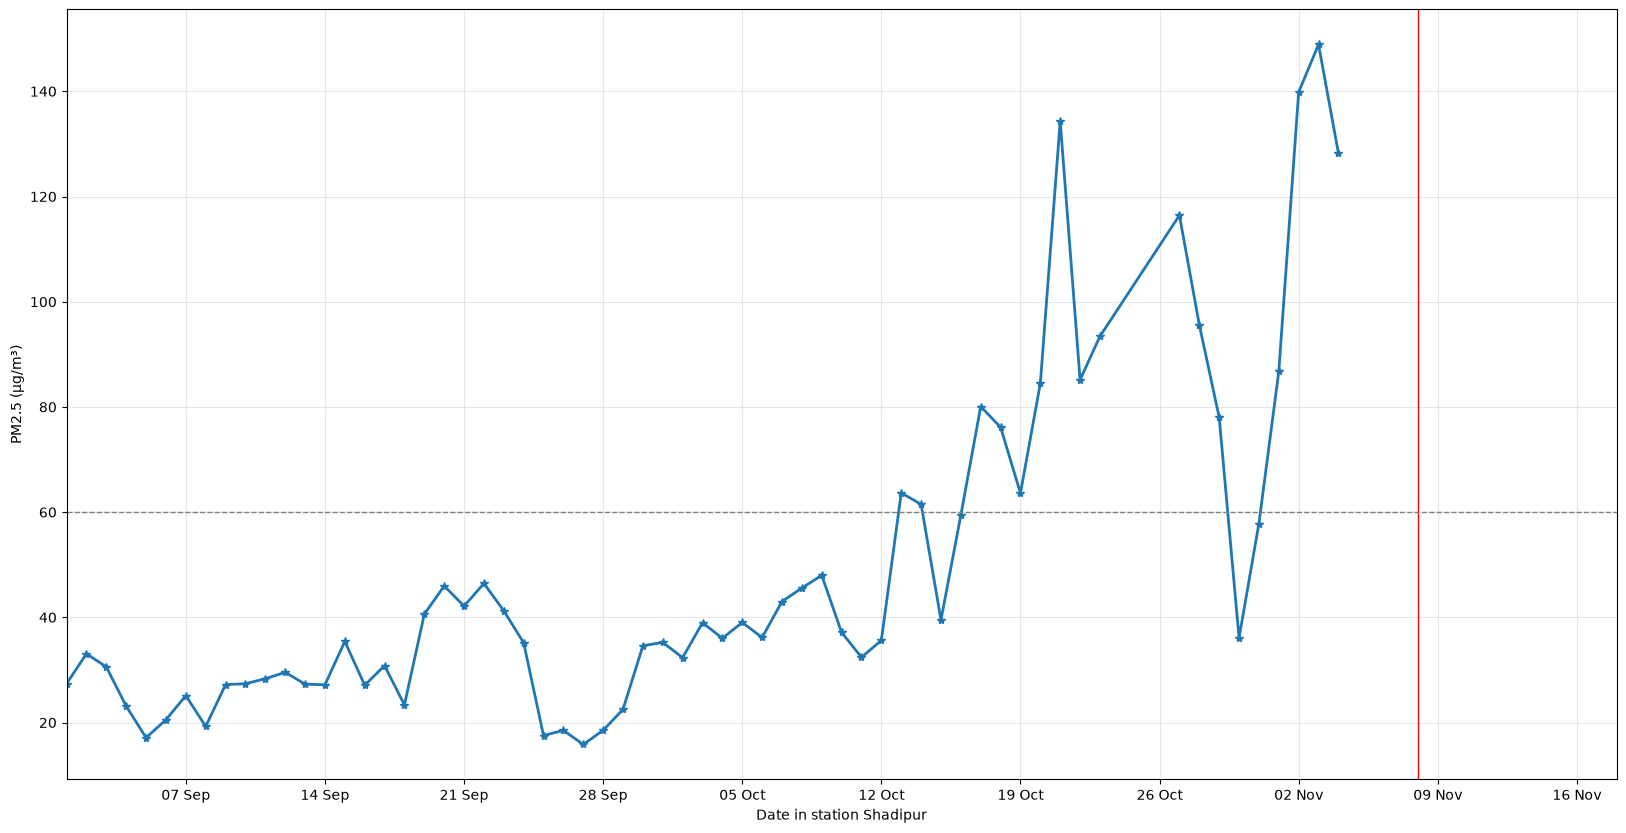

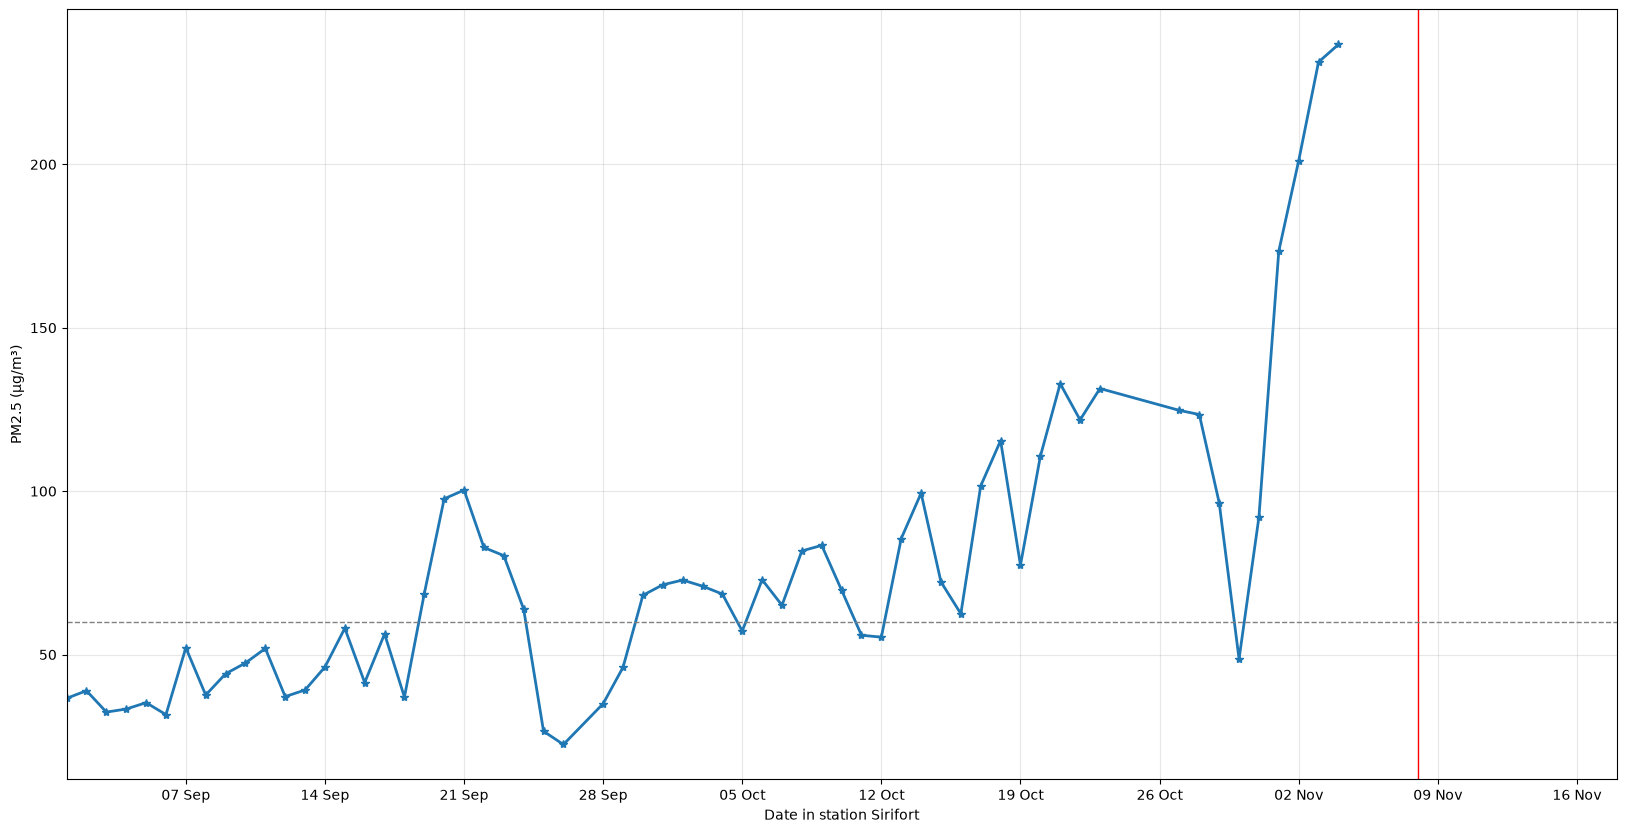

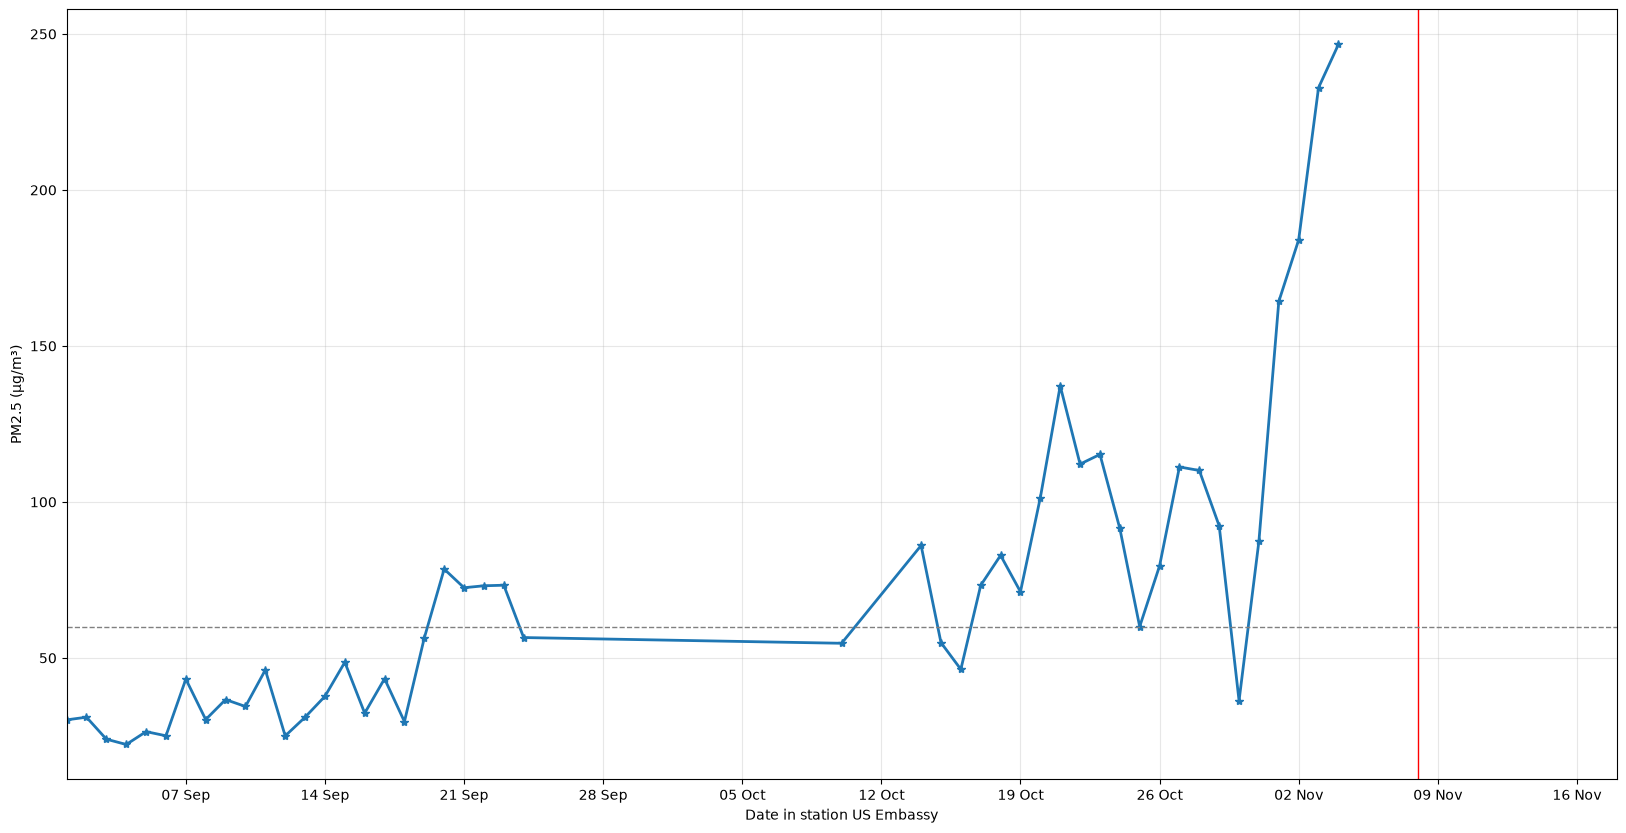

In [7]:
plot_all_data_different_plot(all_record_df, "pm25")

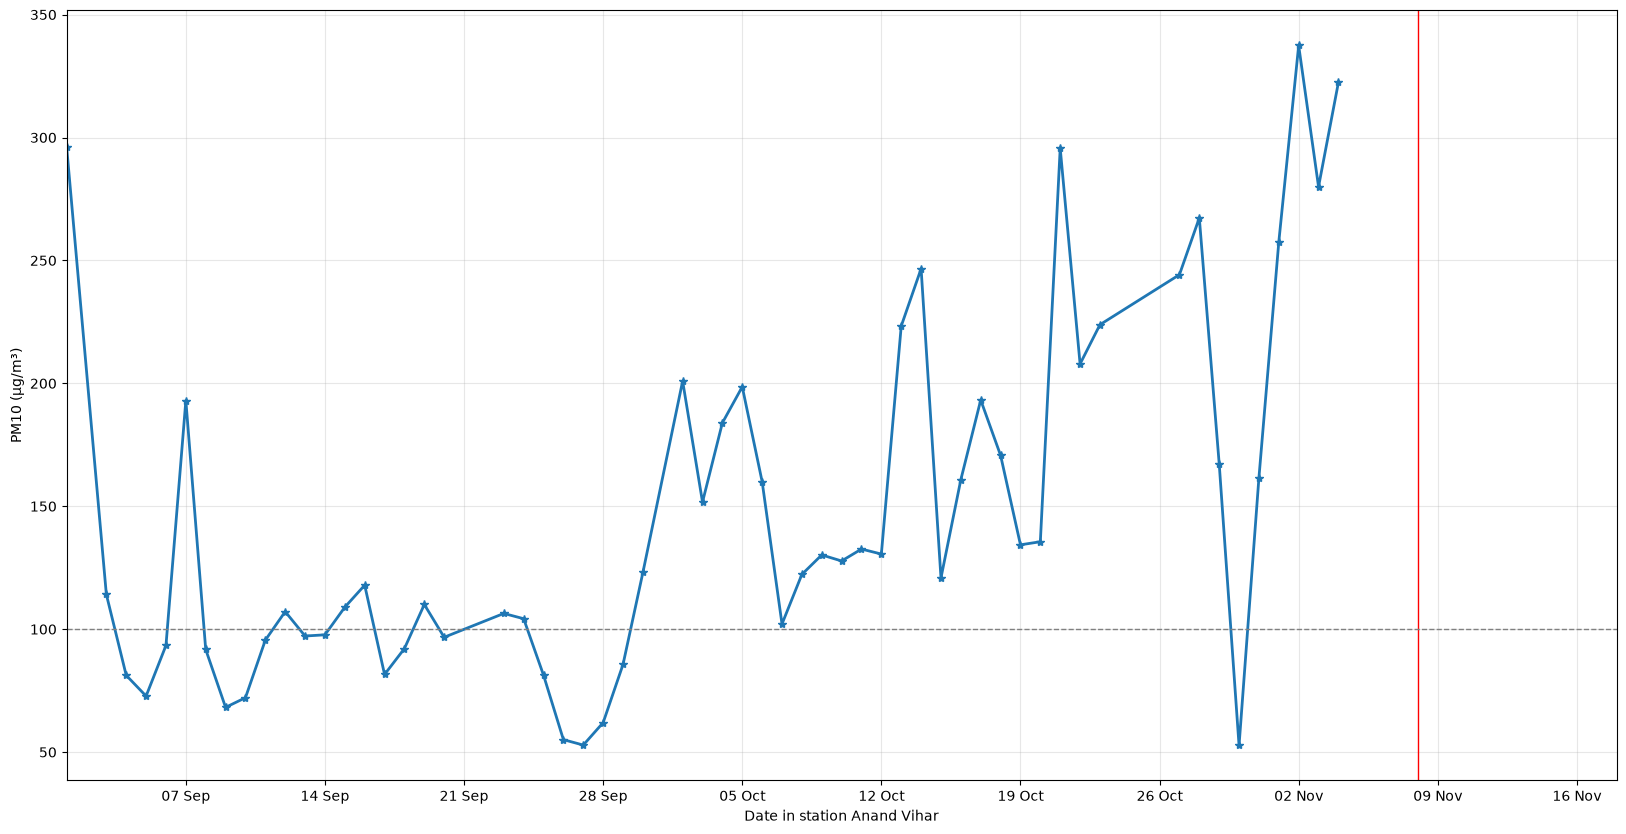

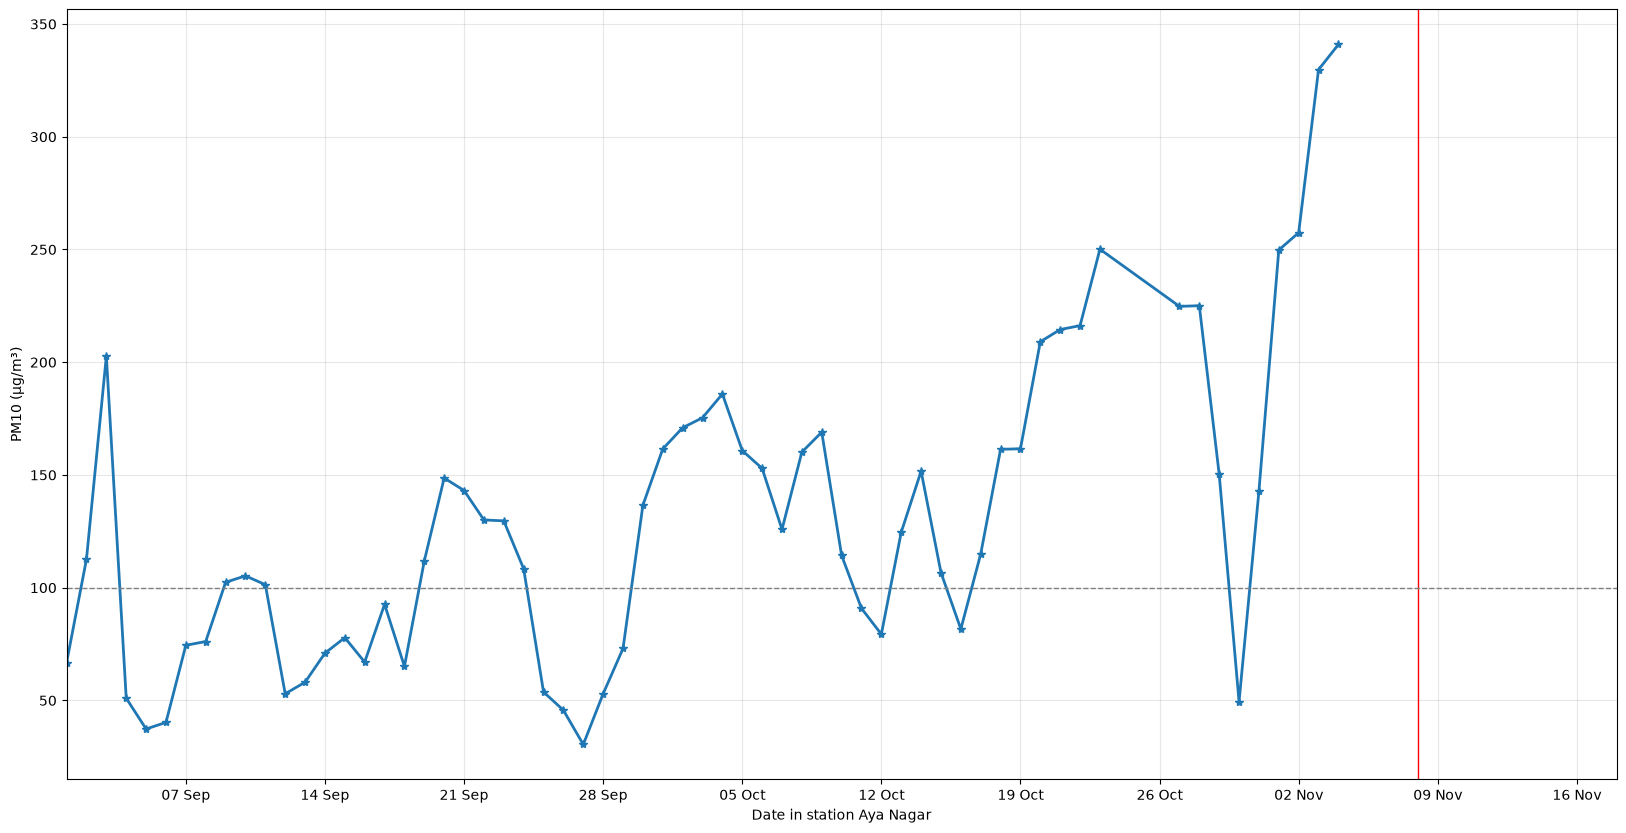

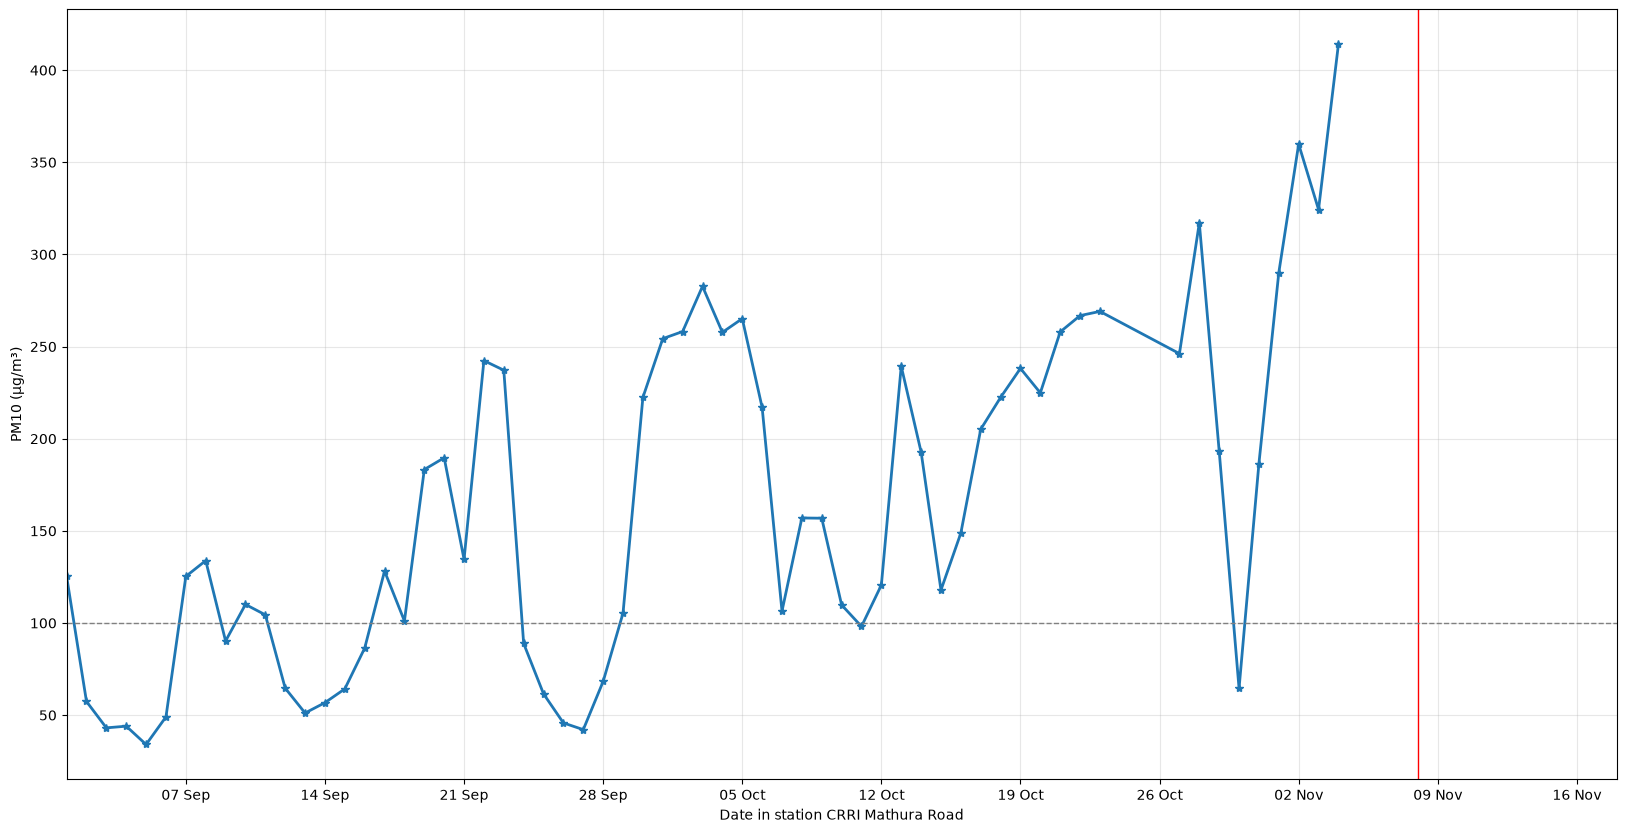

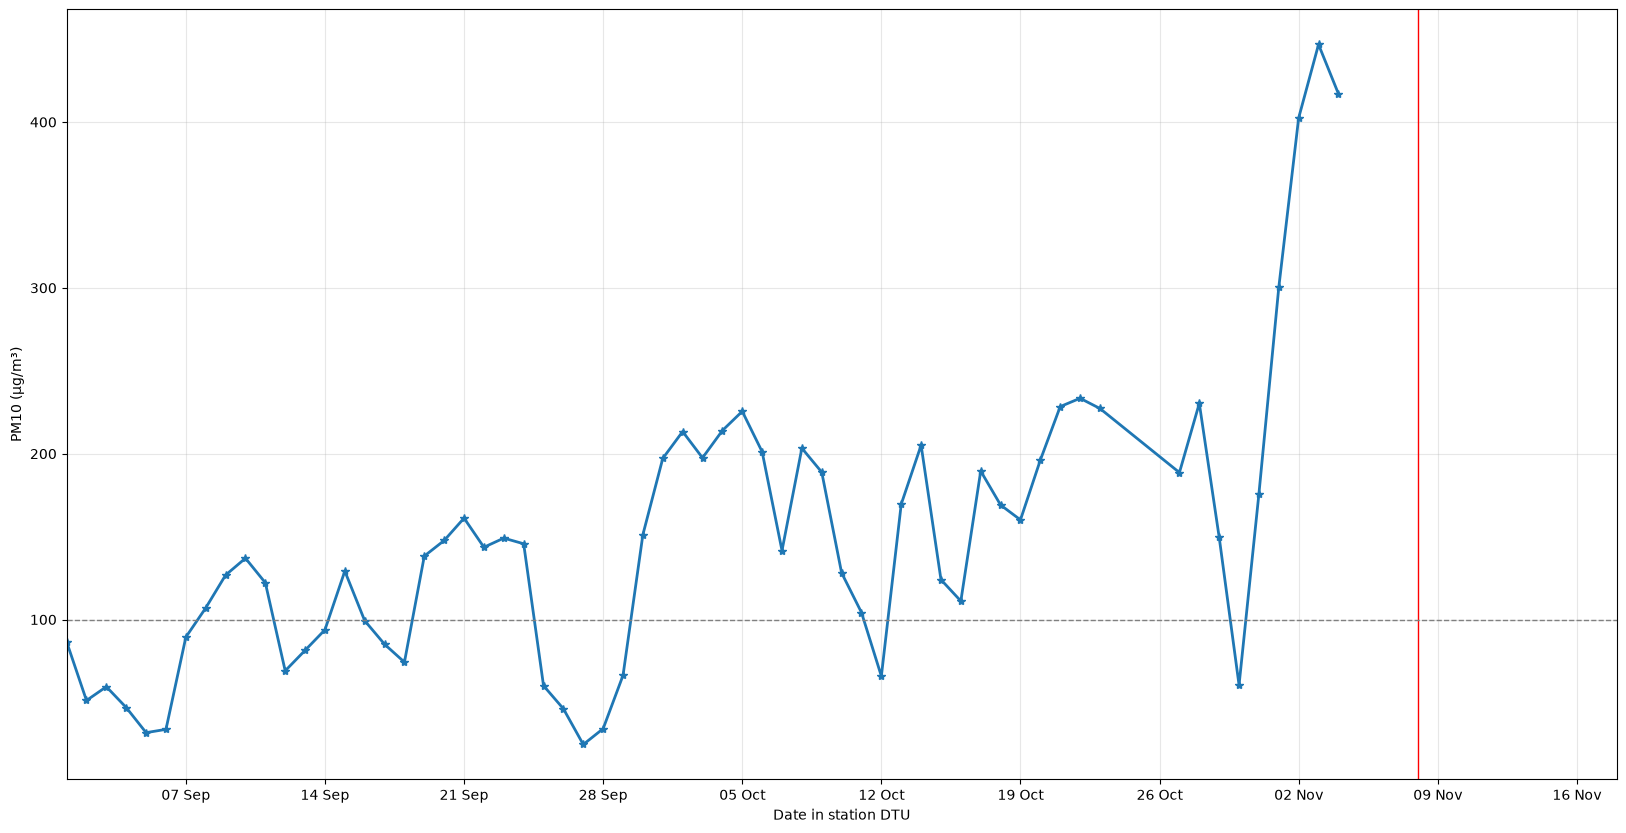

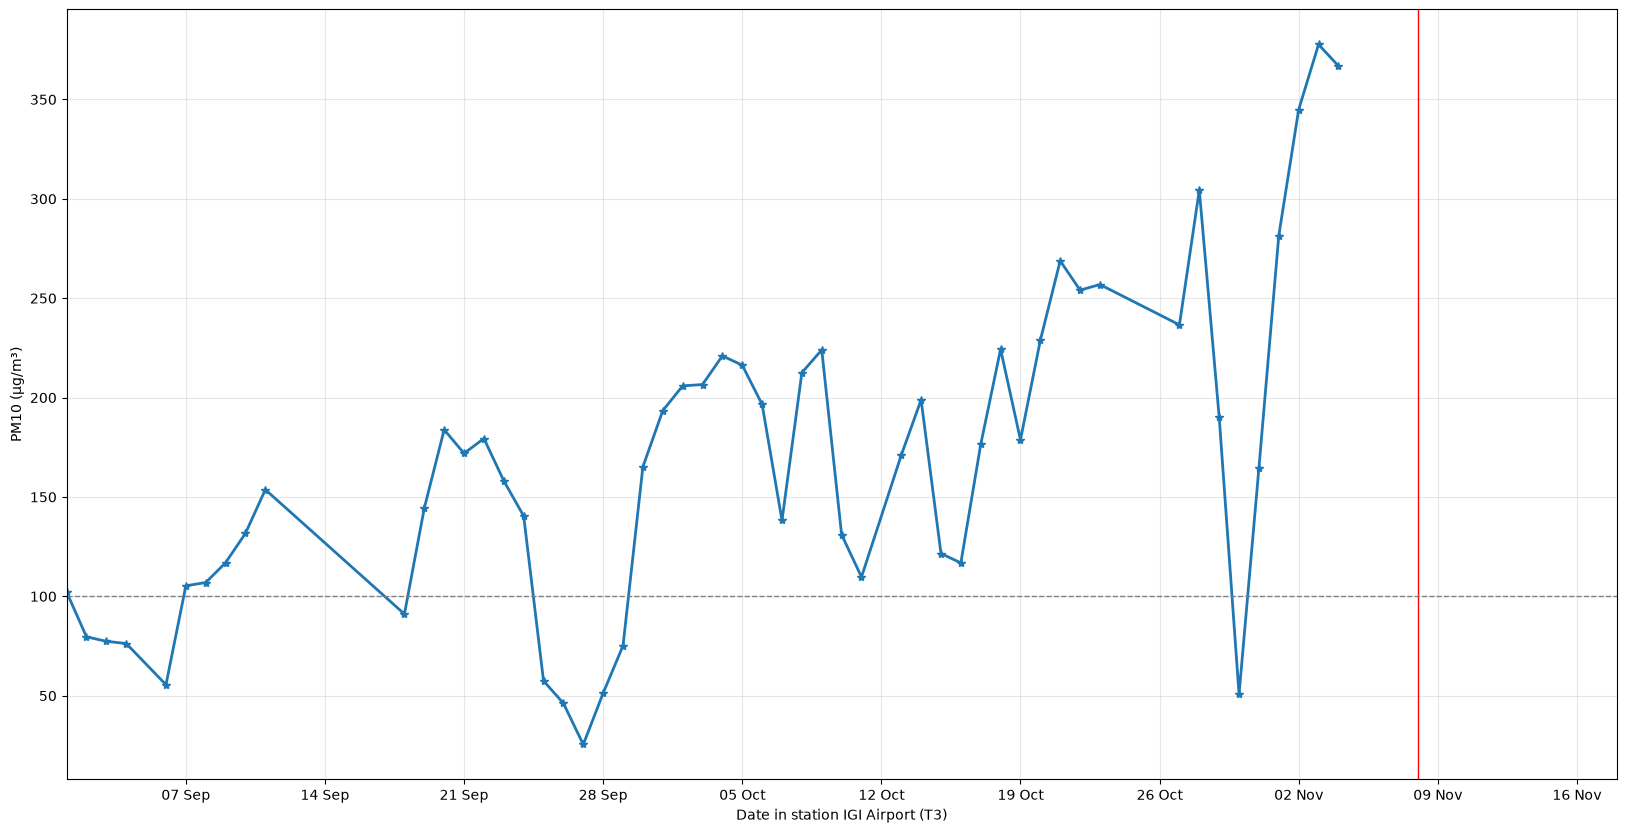

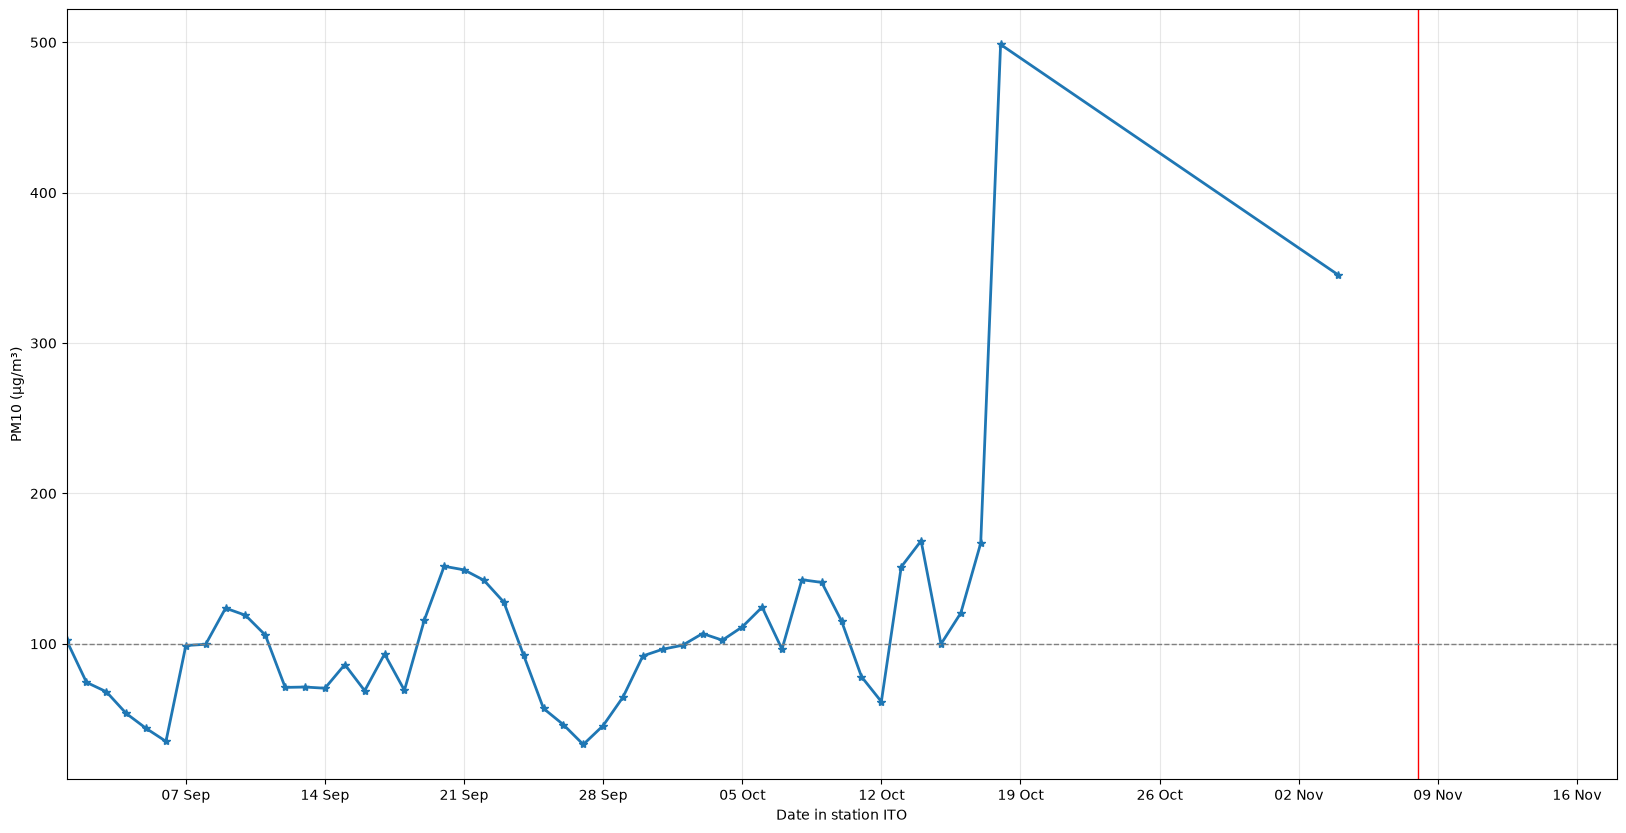

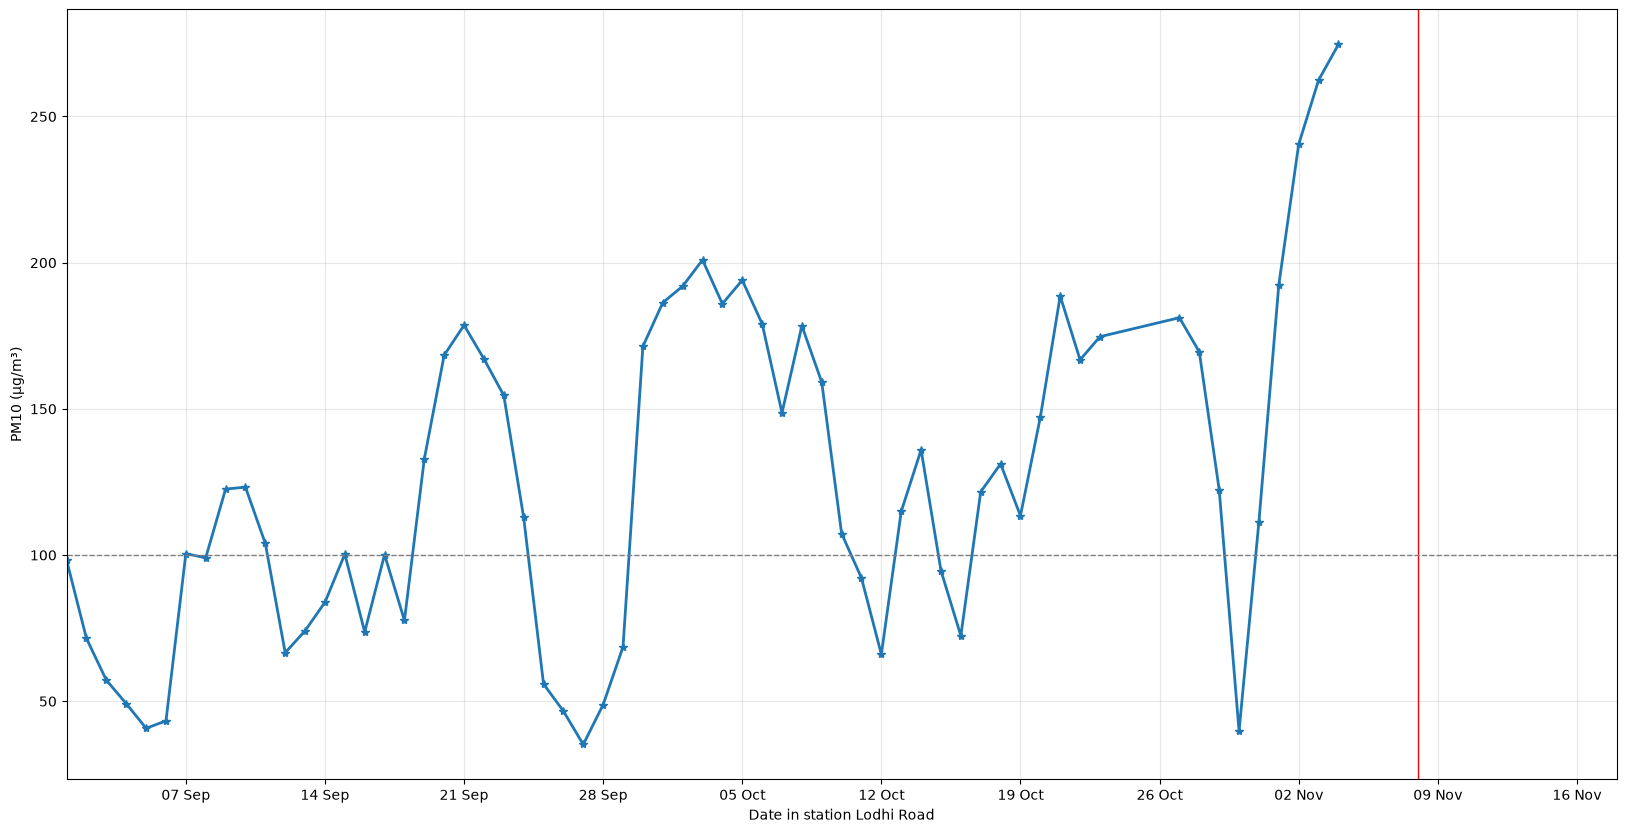

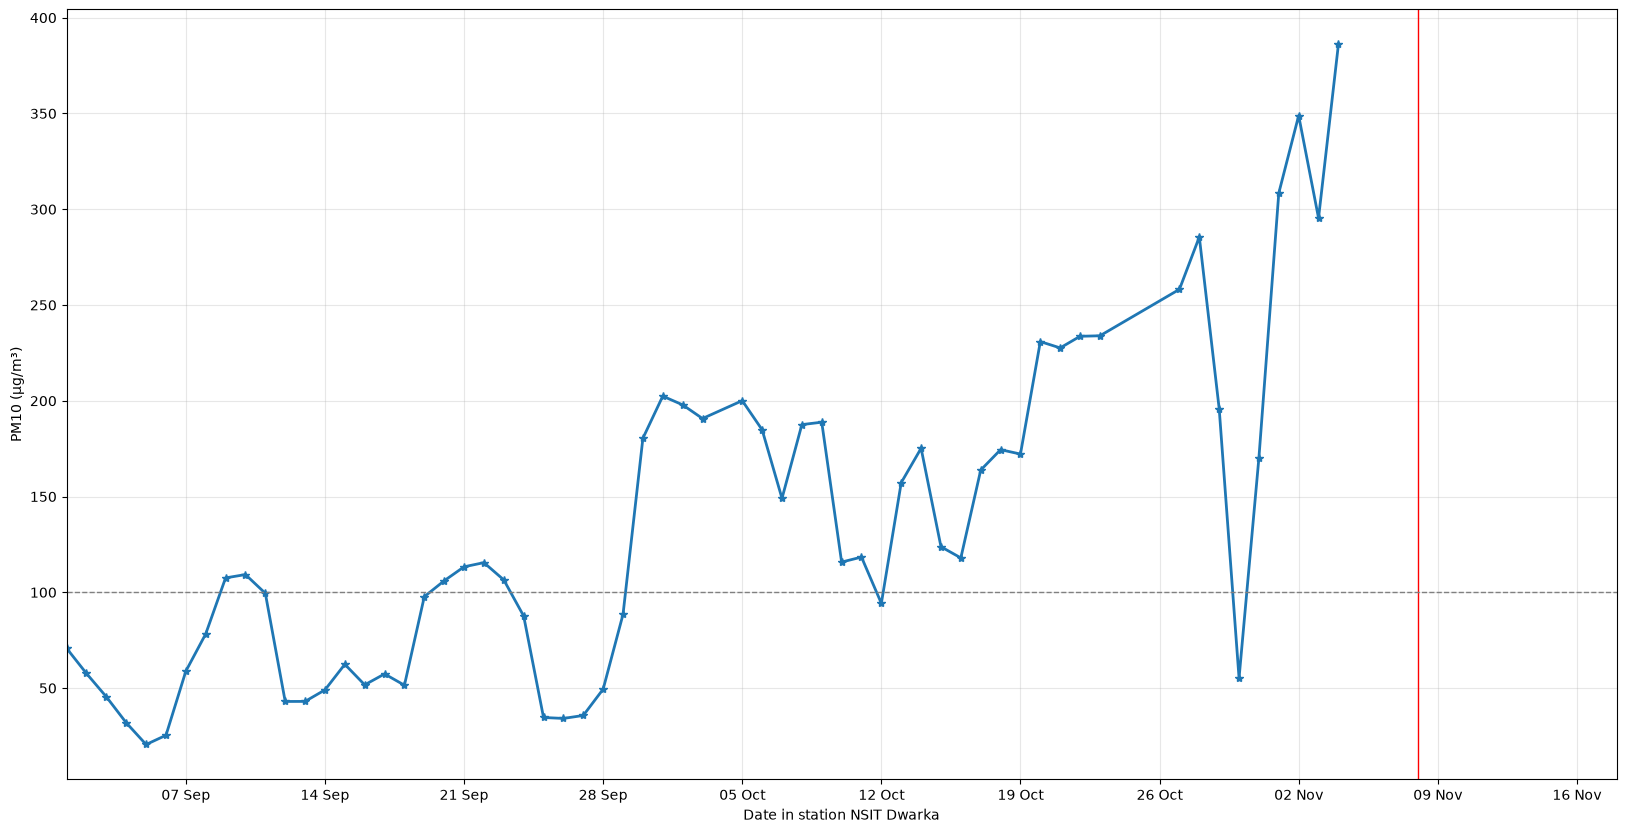

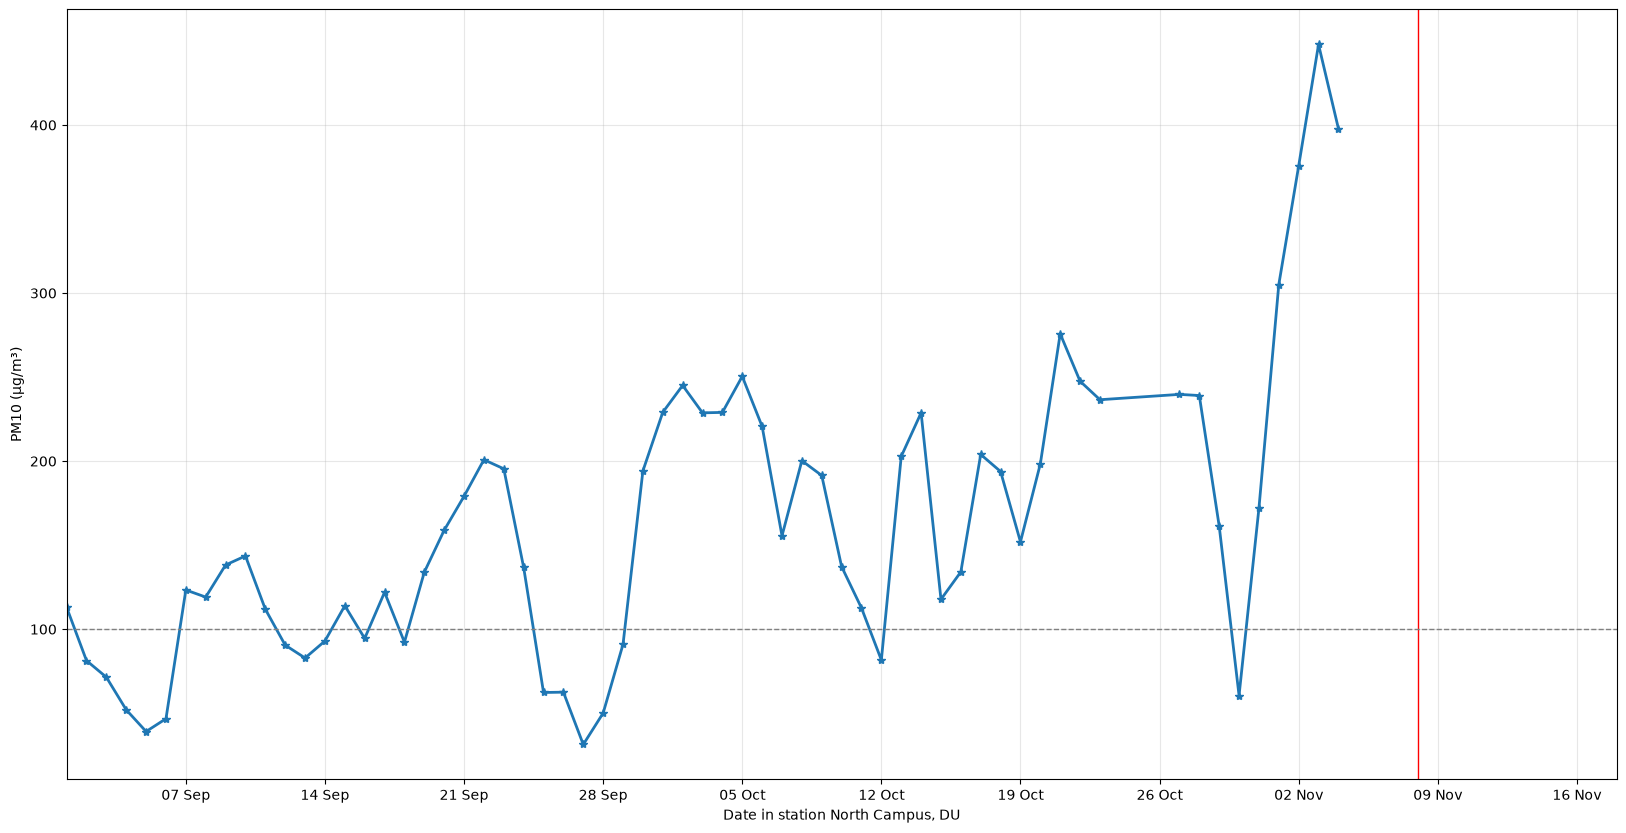

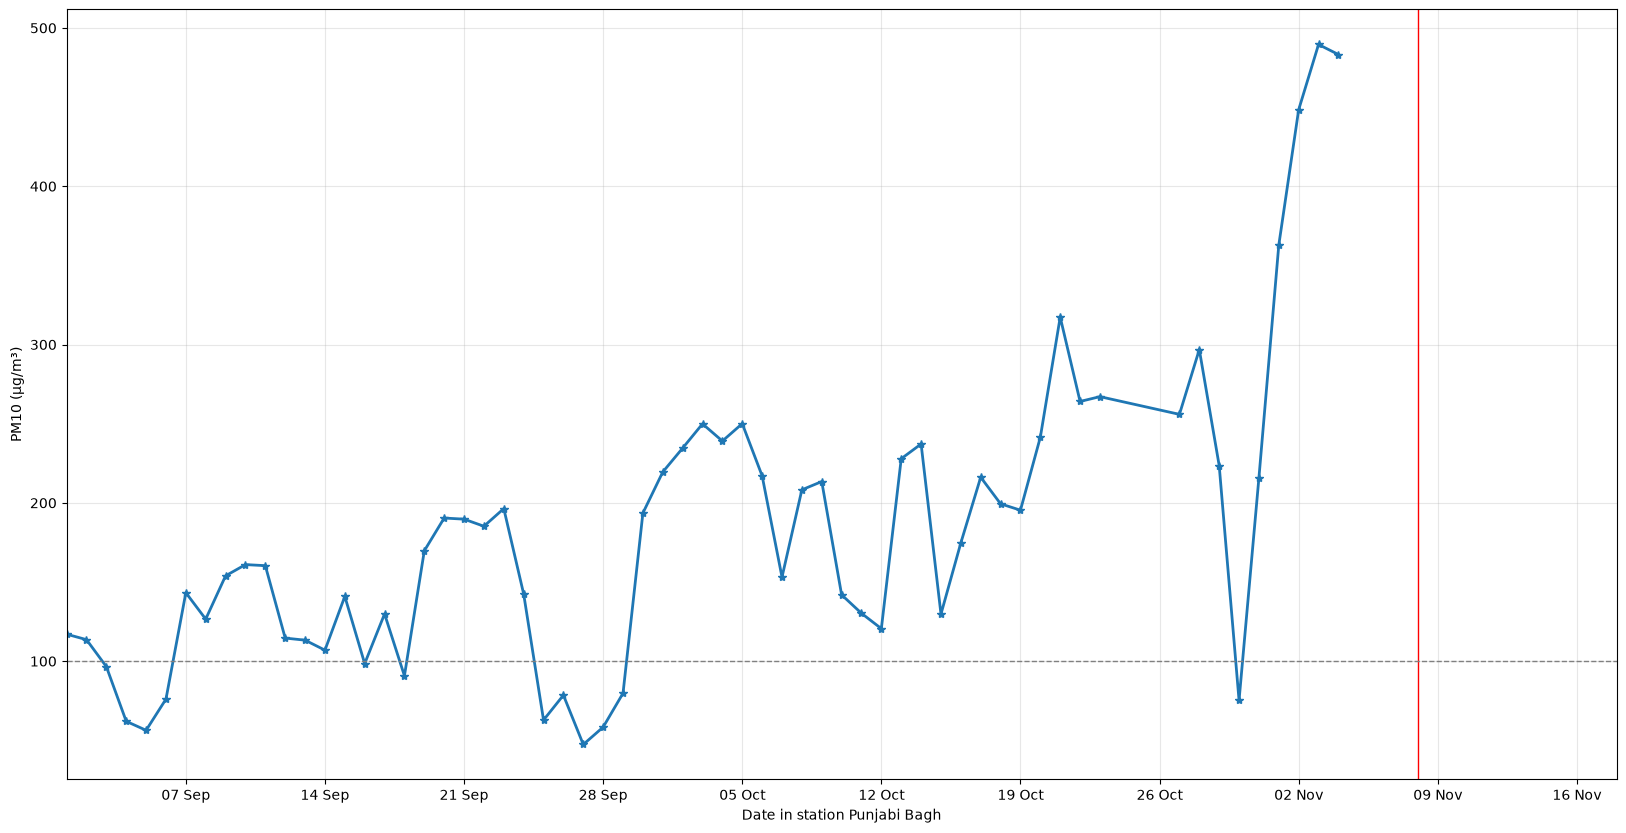

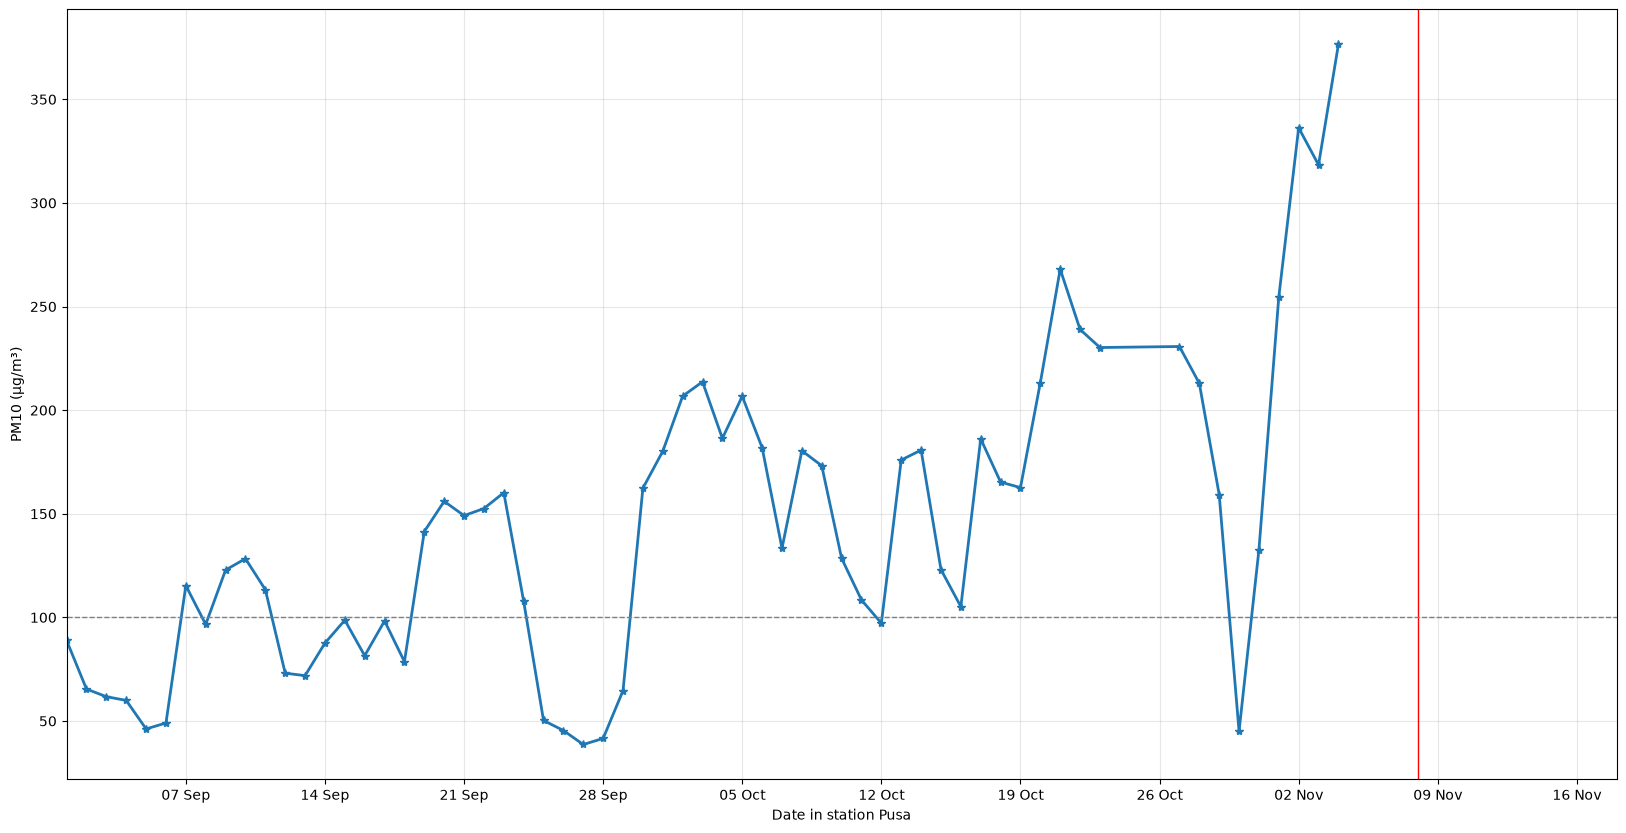

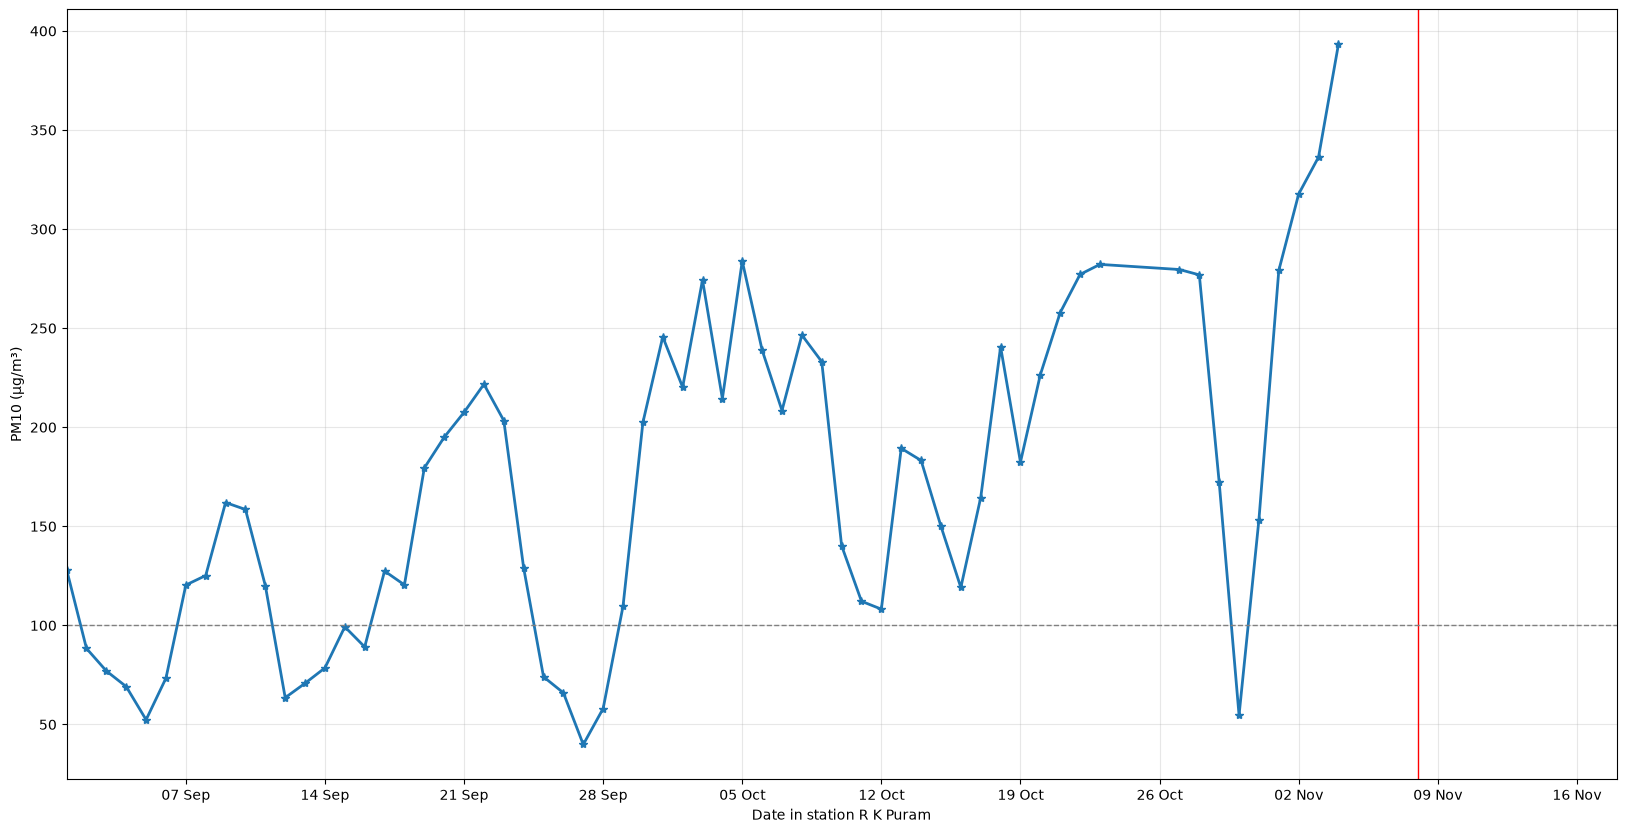

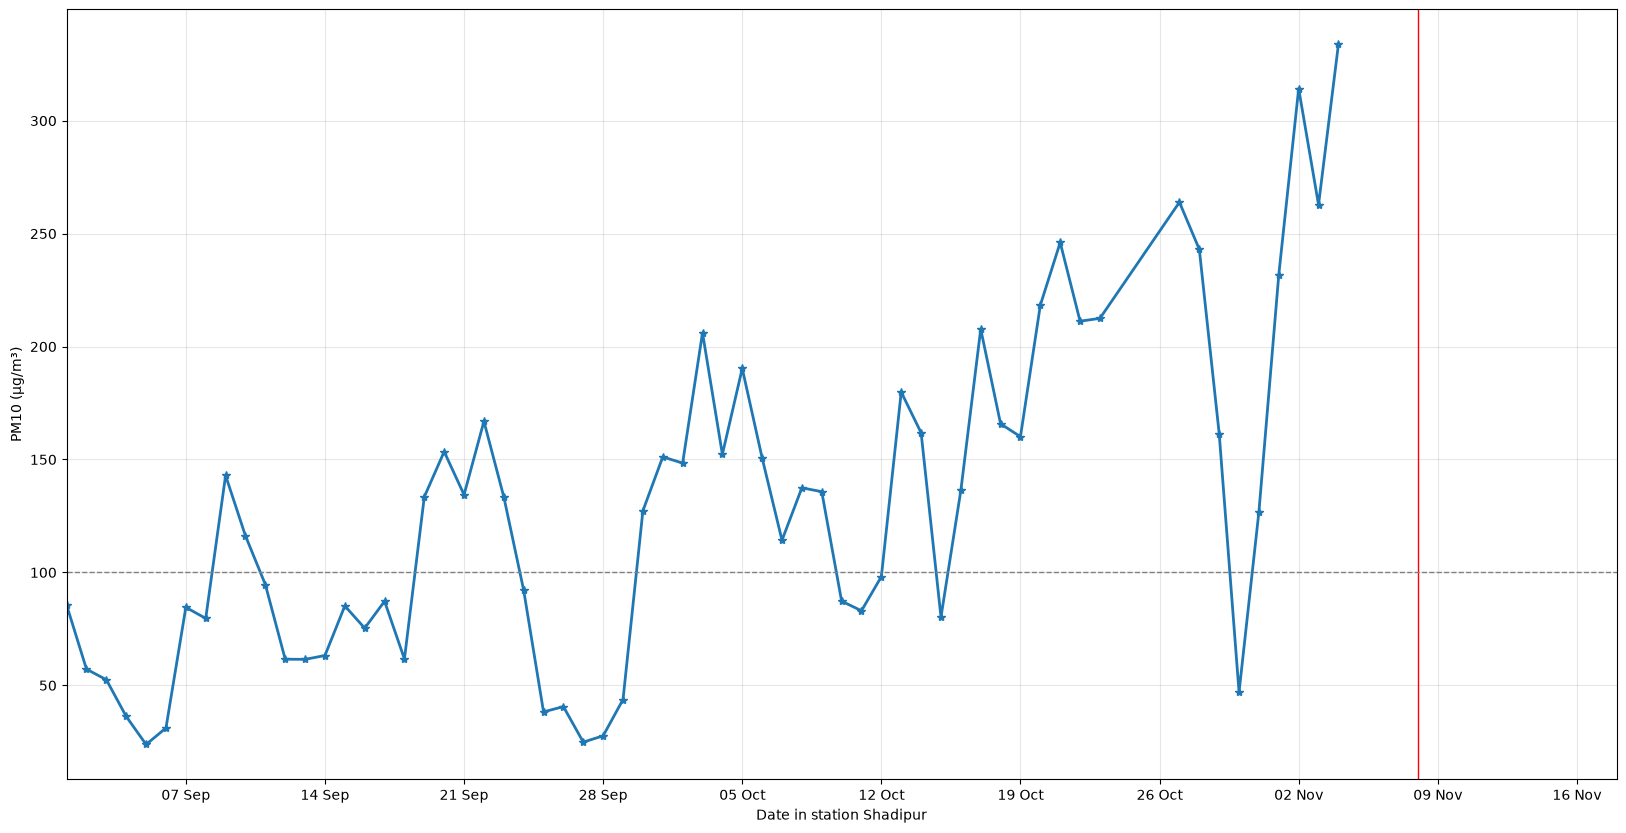

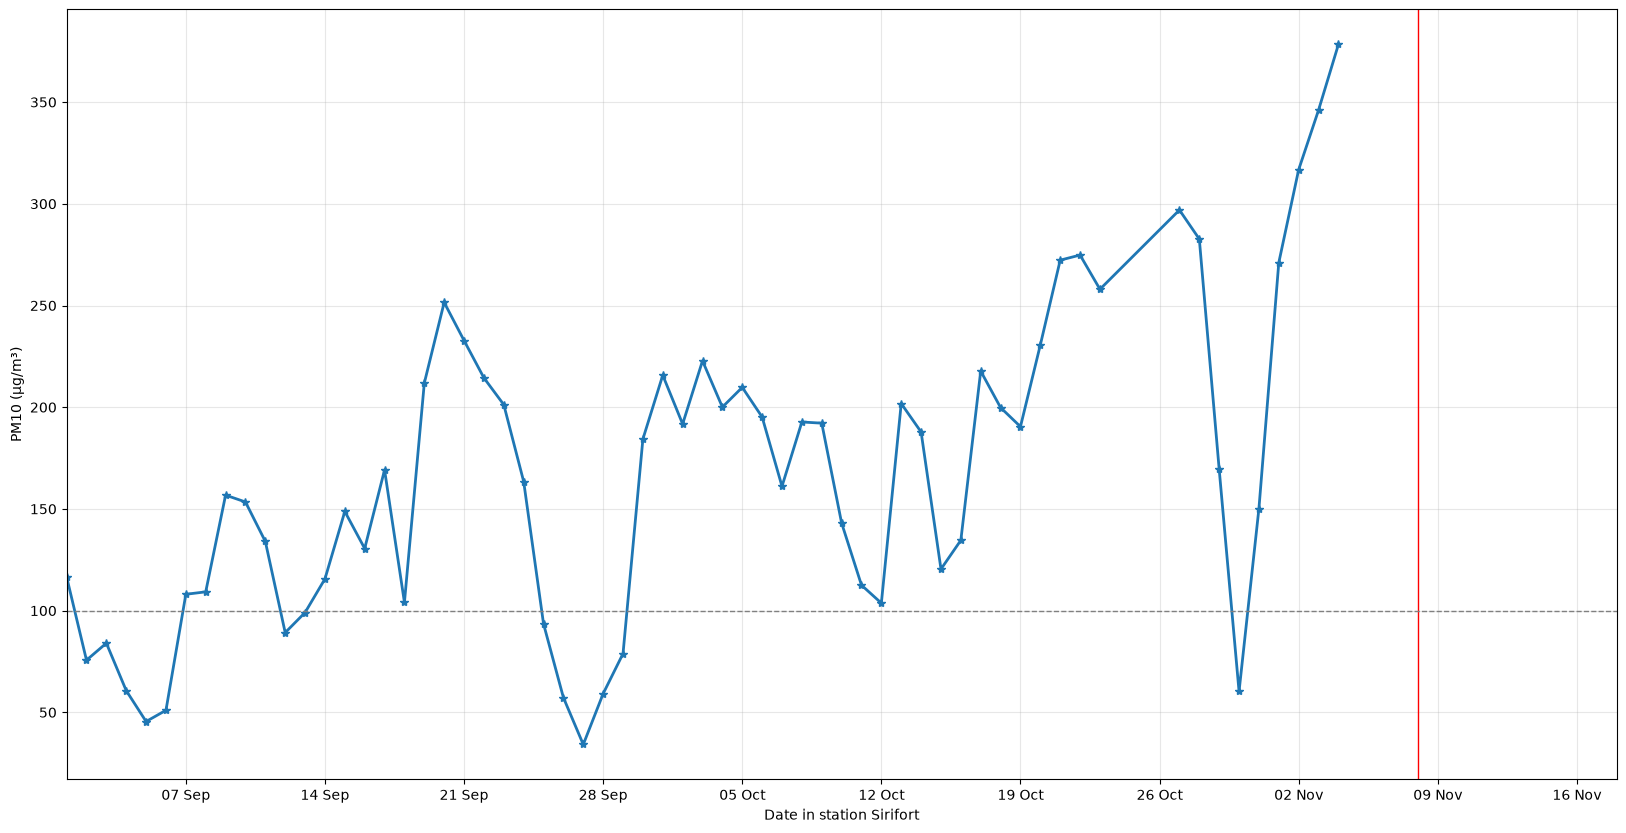

In [8]:
plot_all_data_different_plot(all_record_df, "pm10")

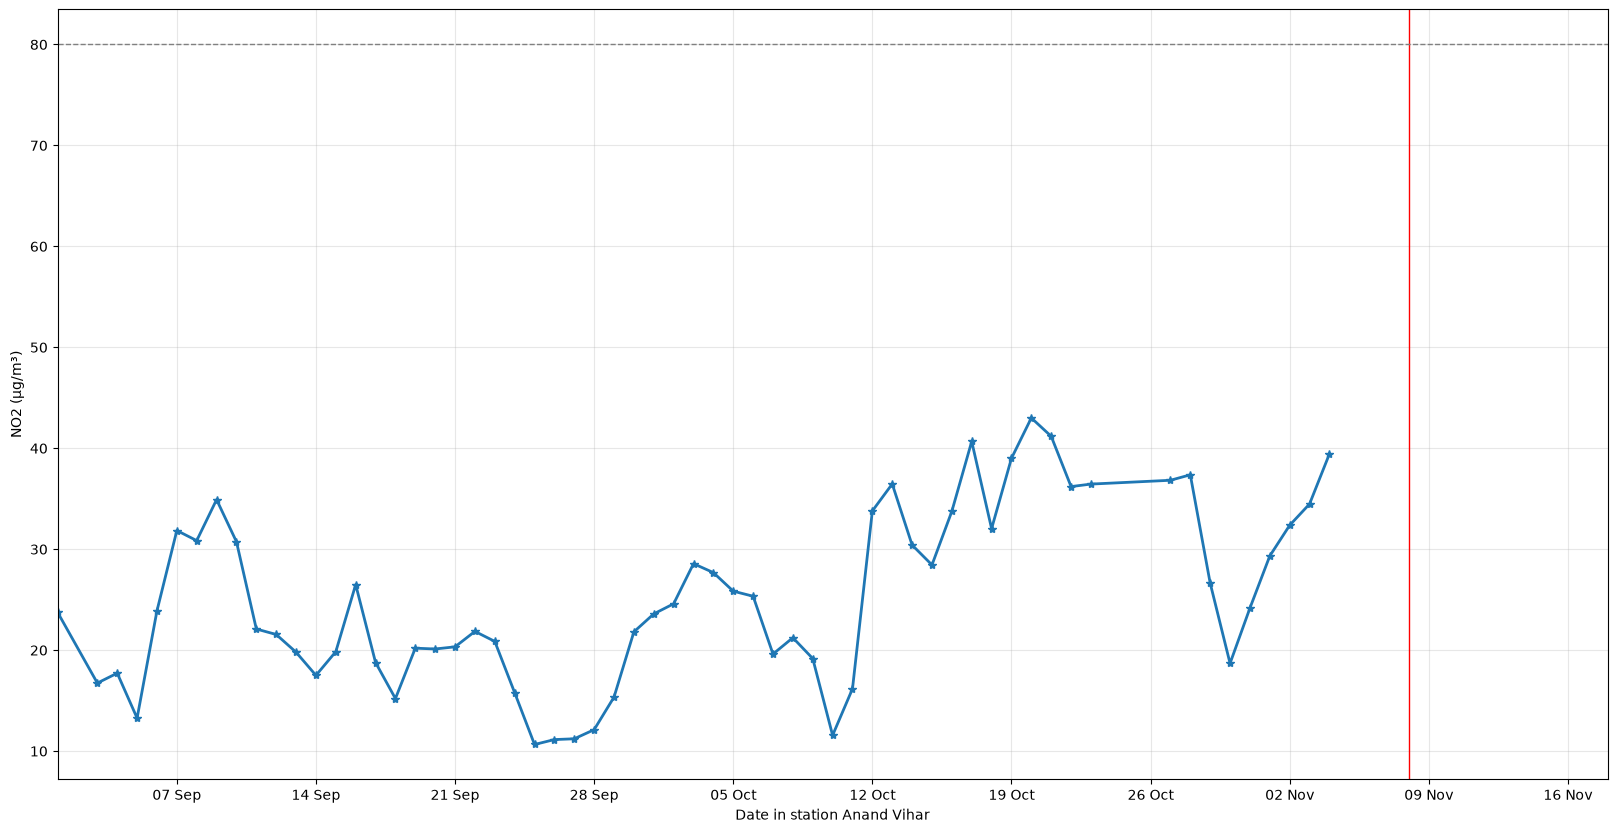

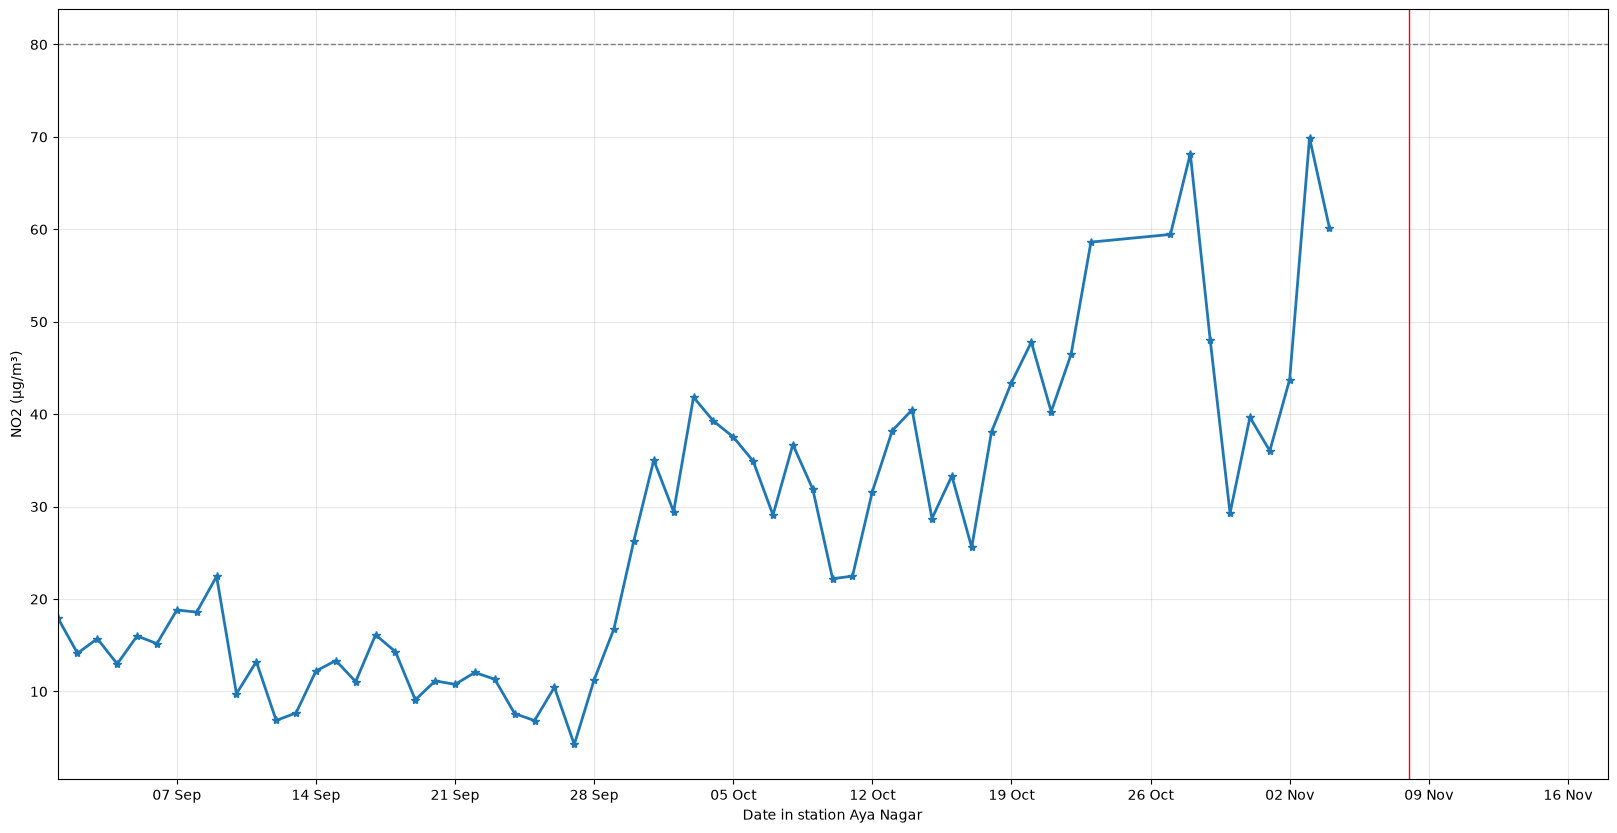

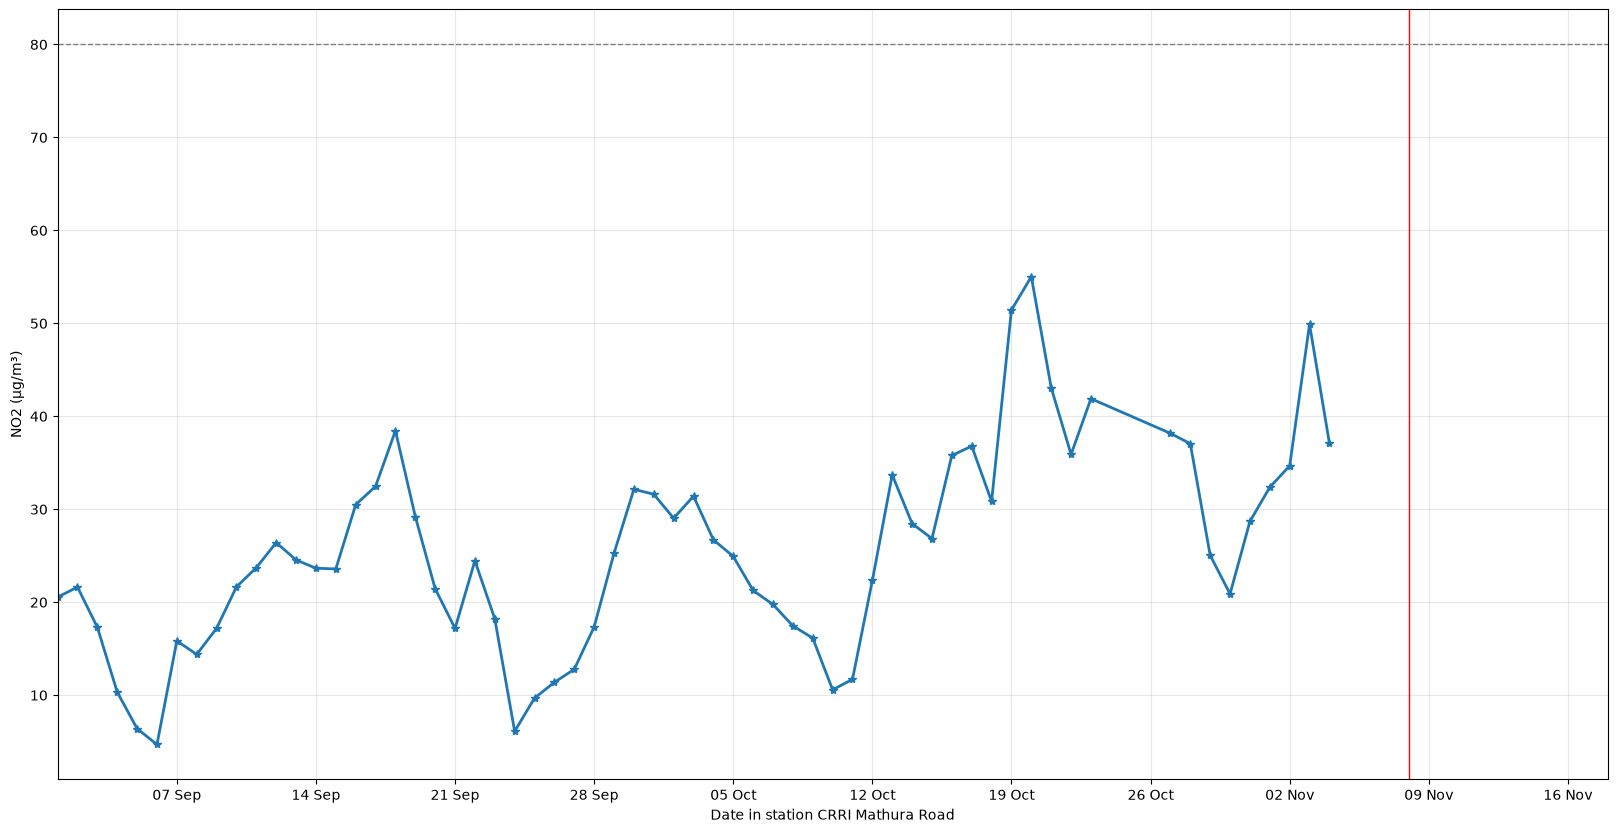

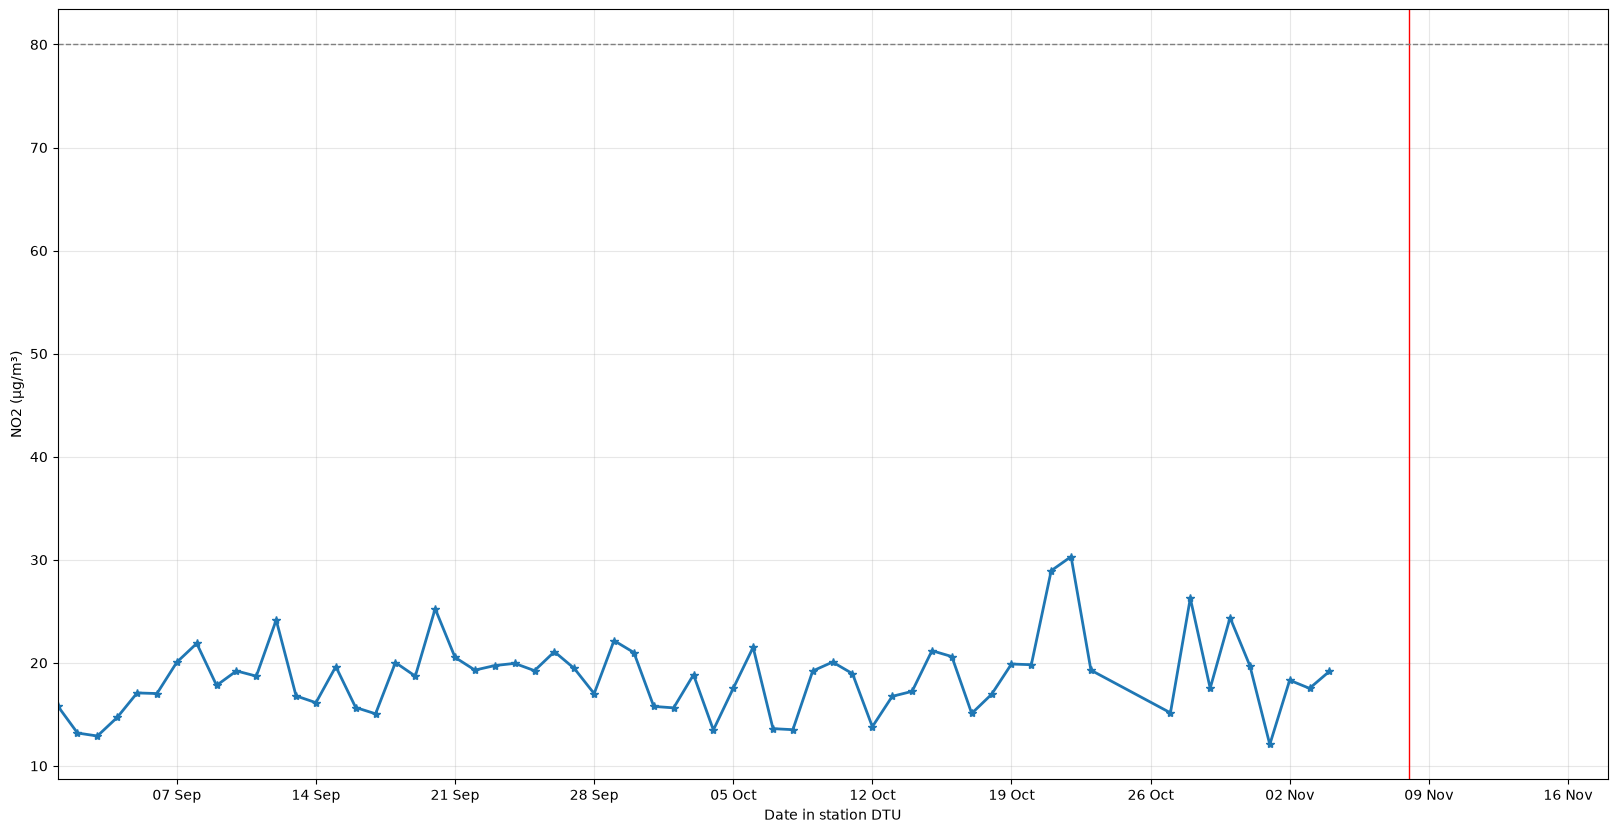

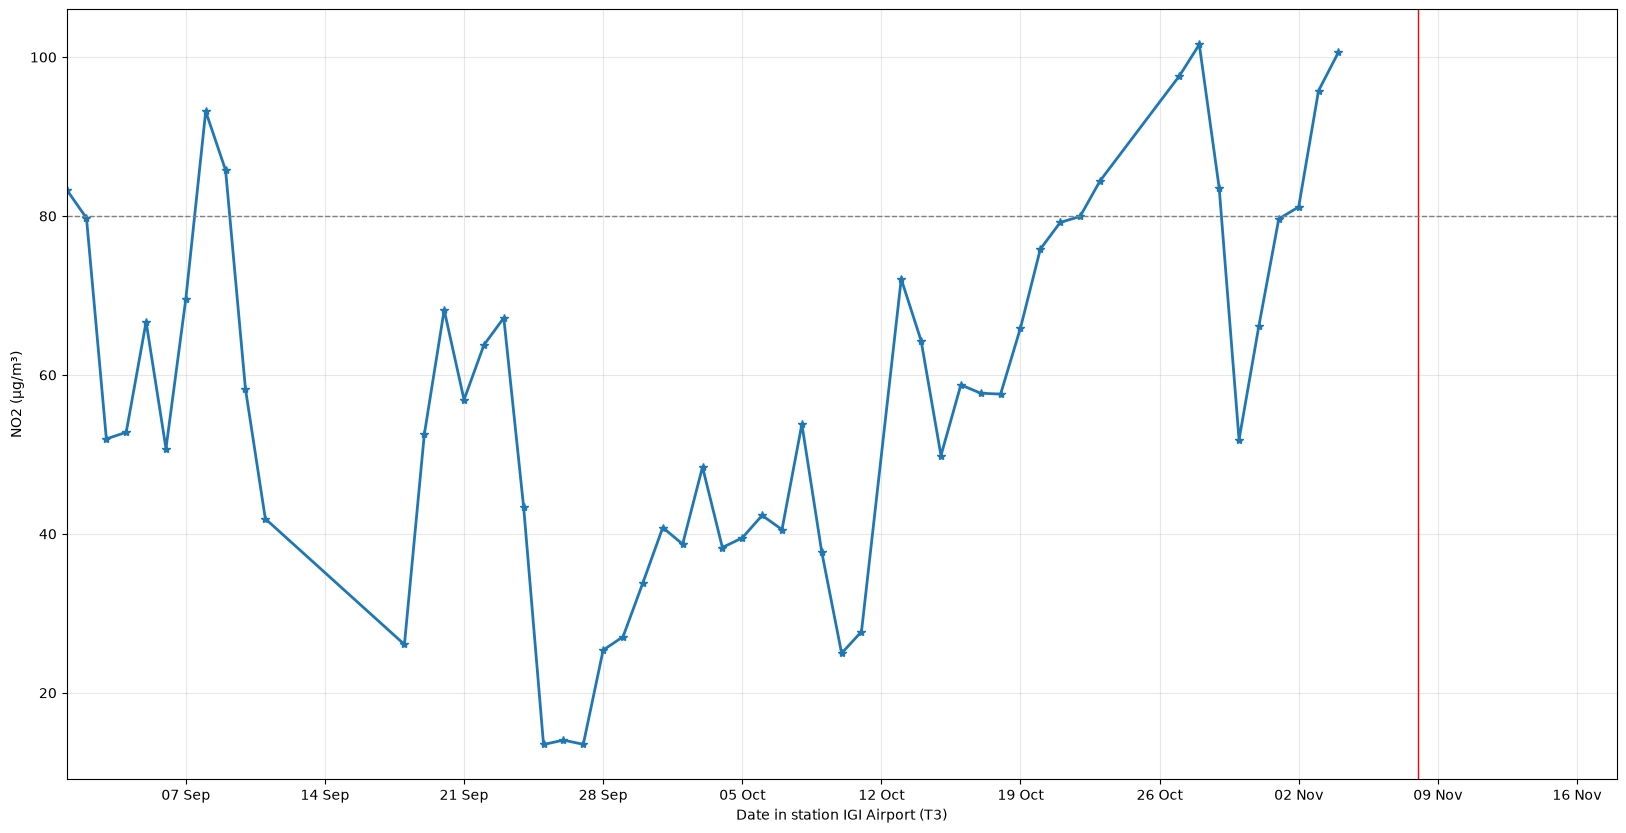

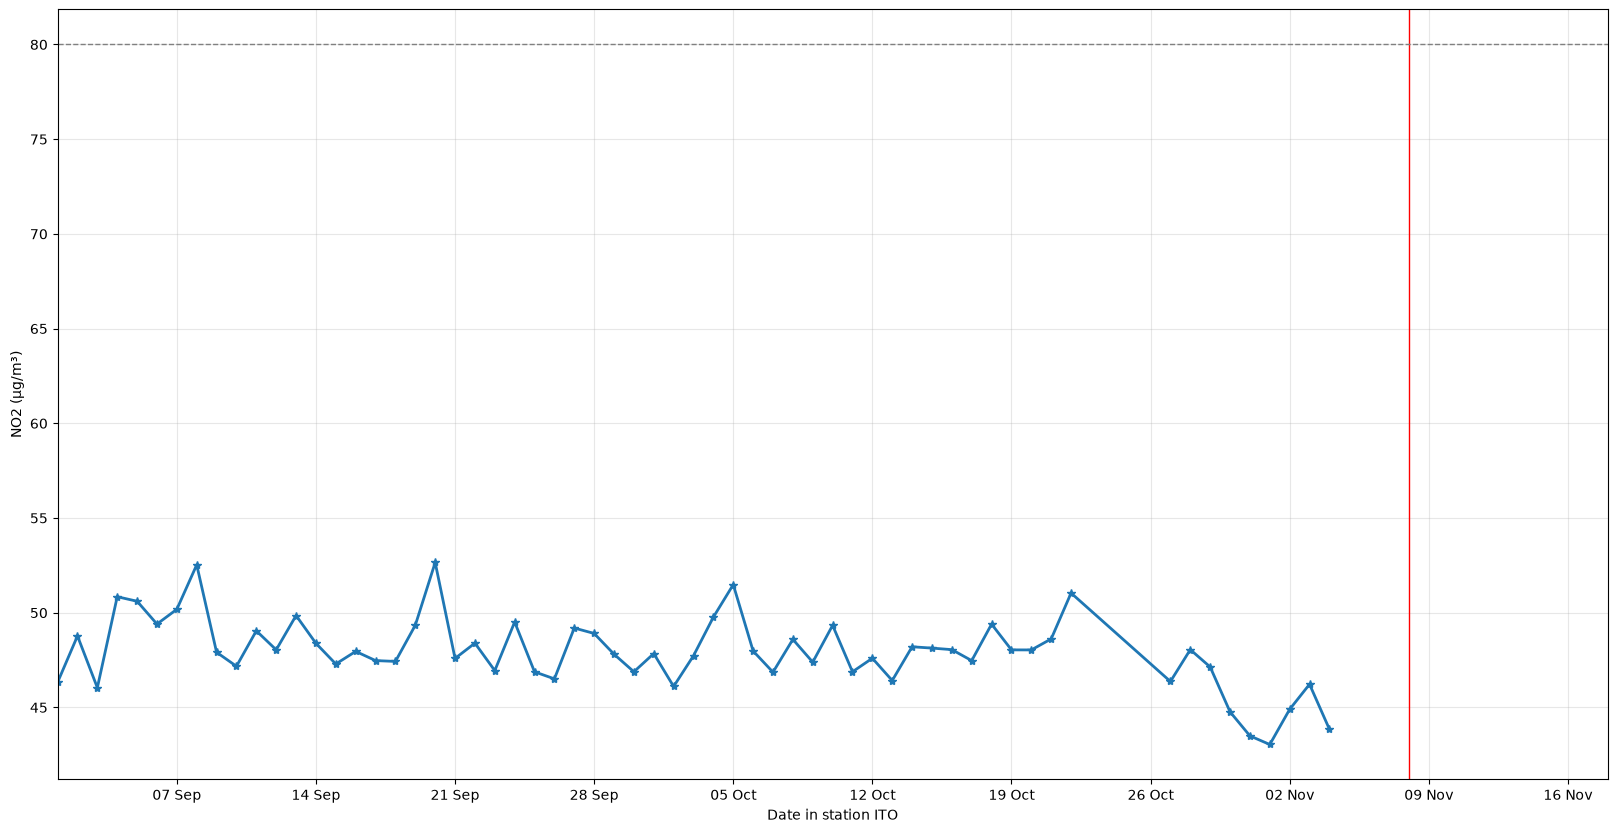

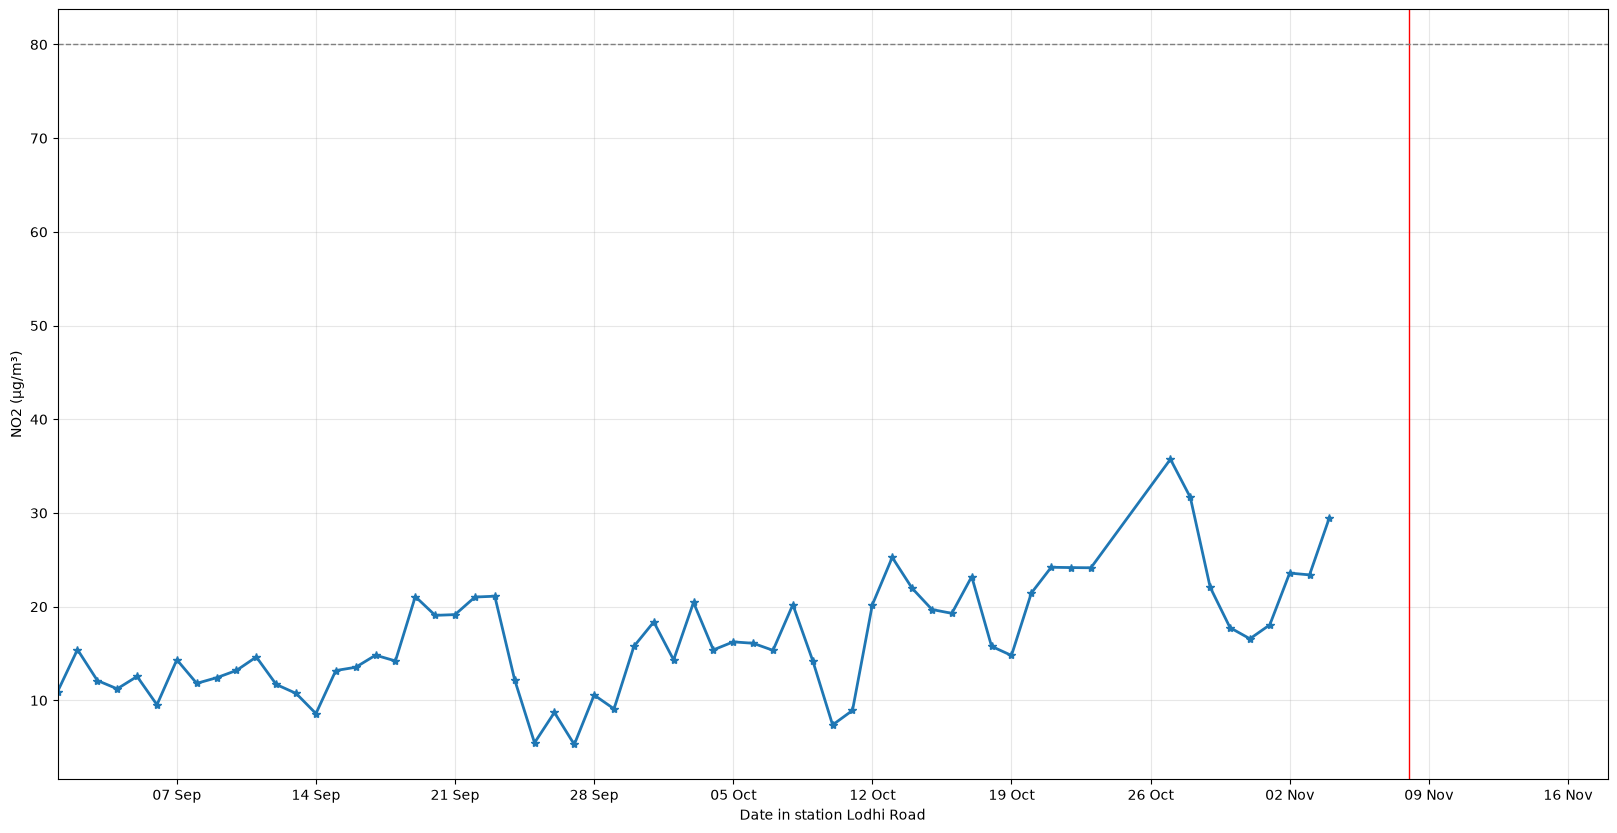

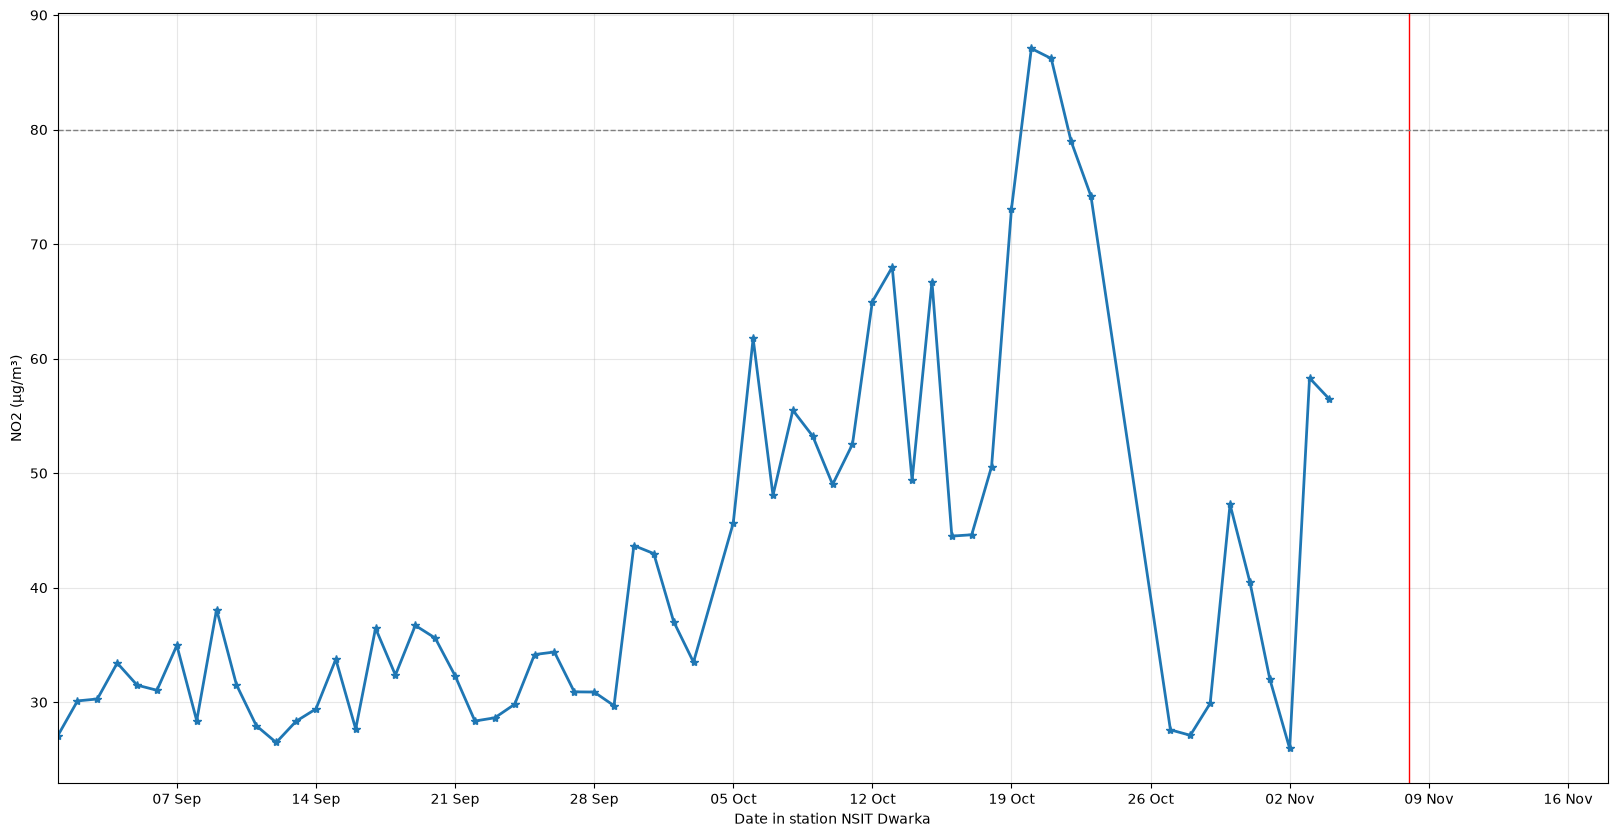

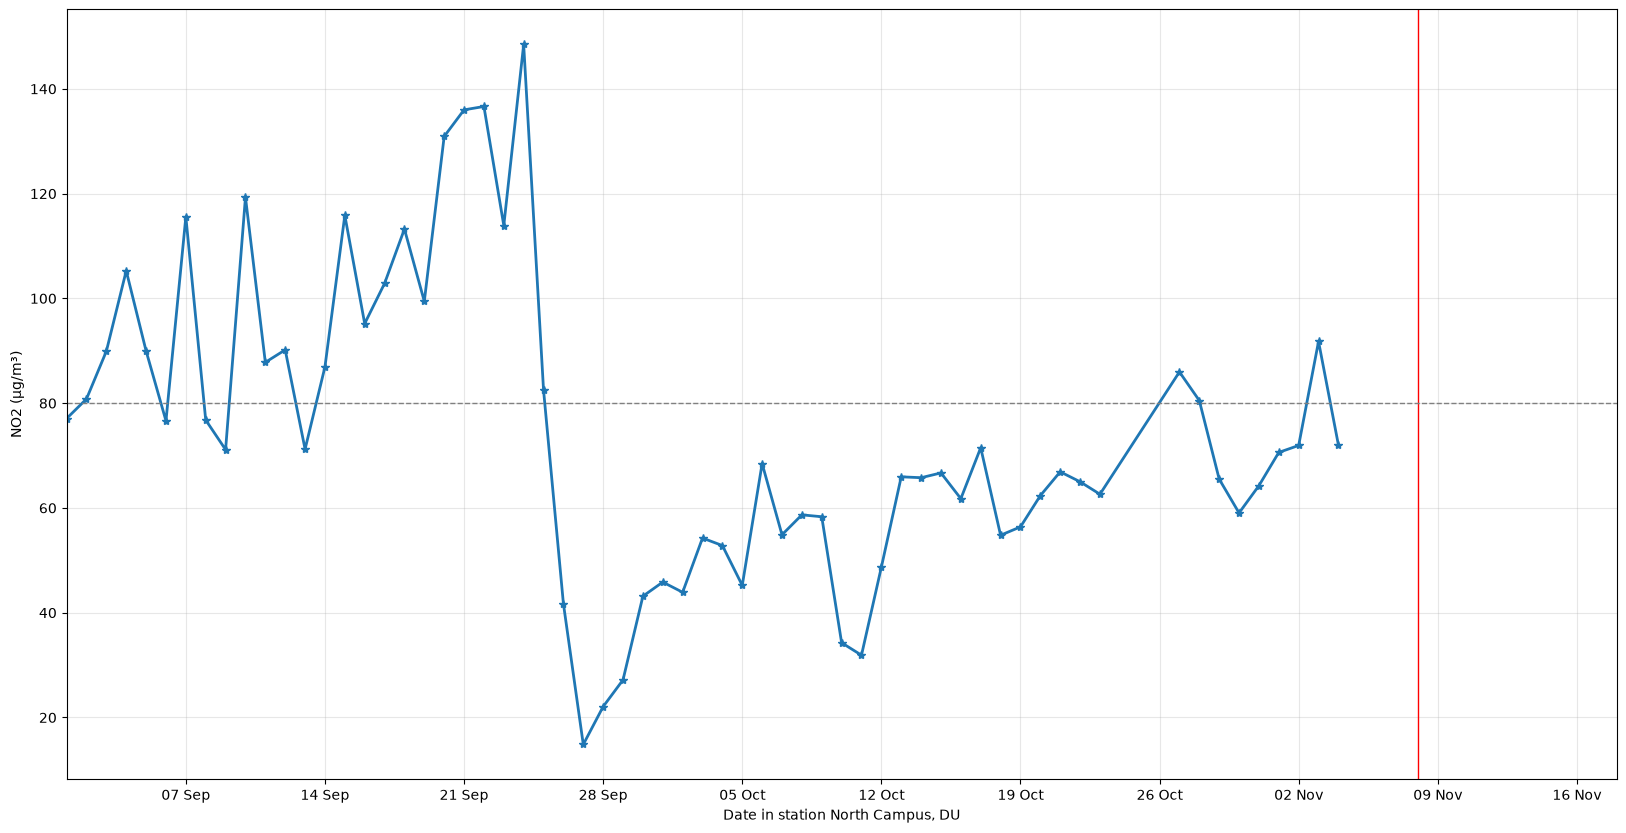

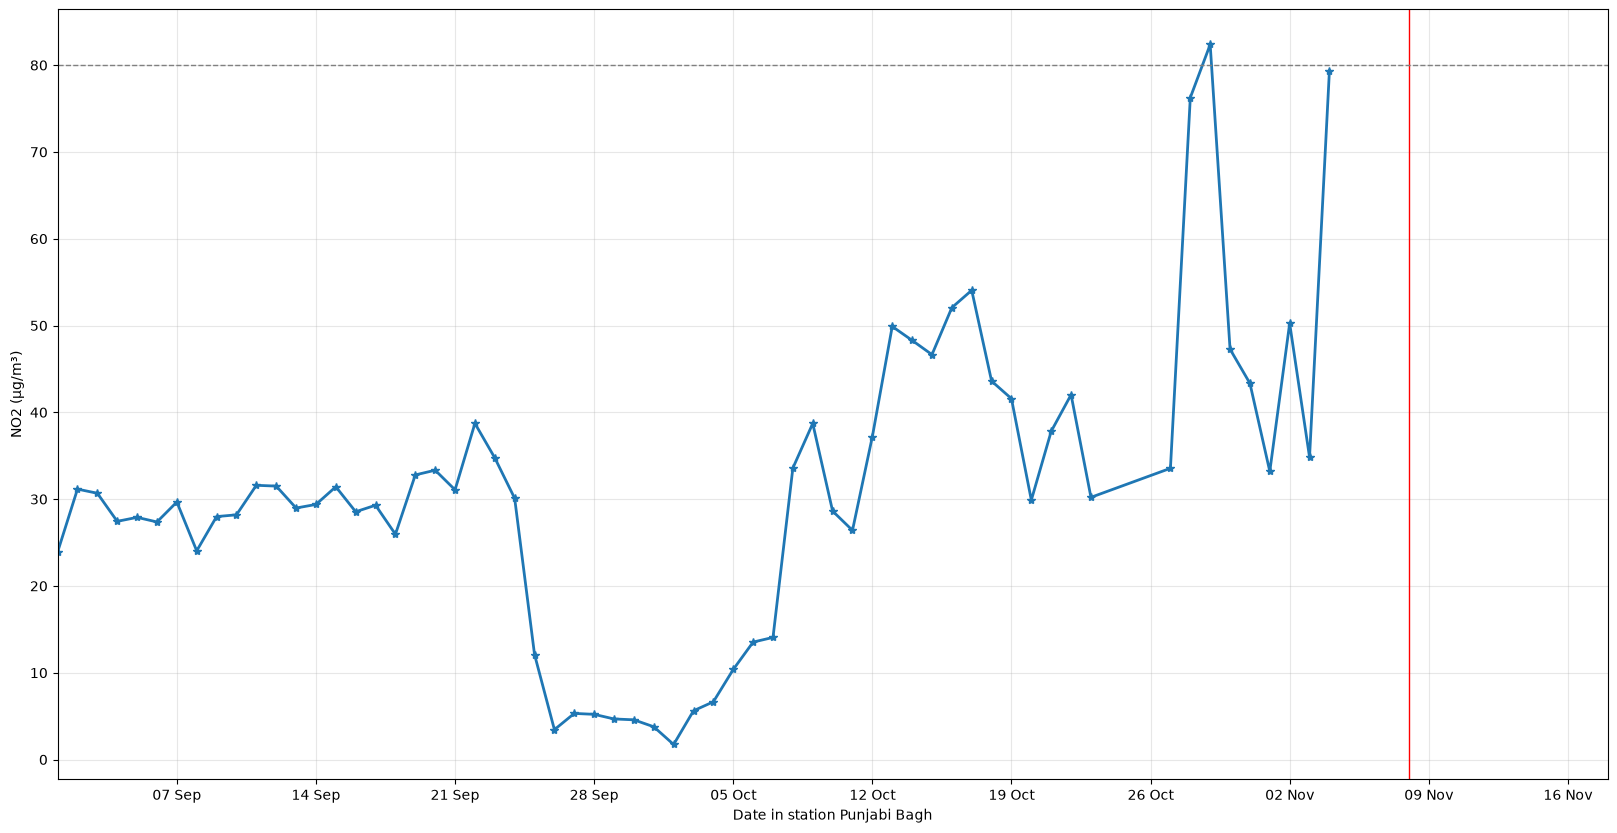

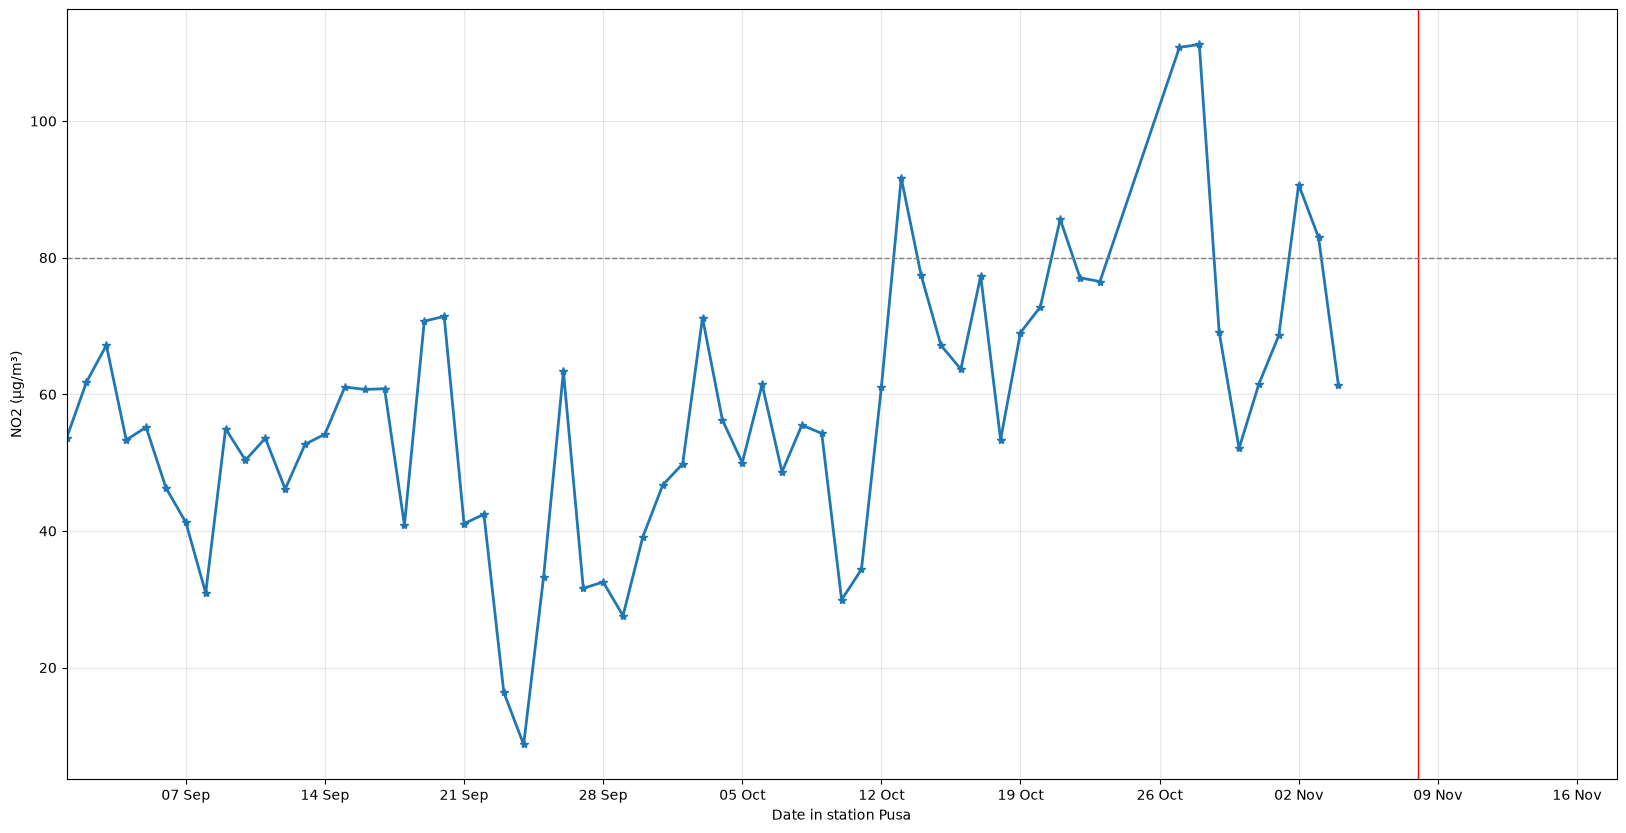

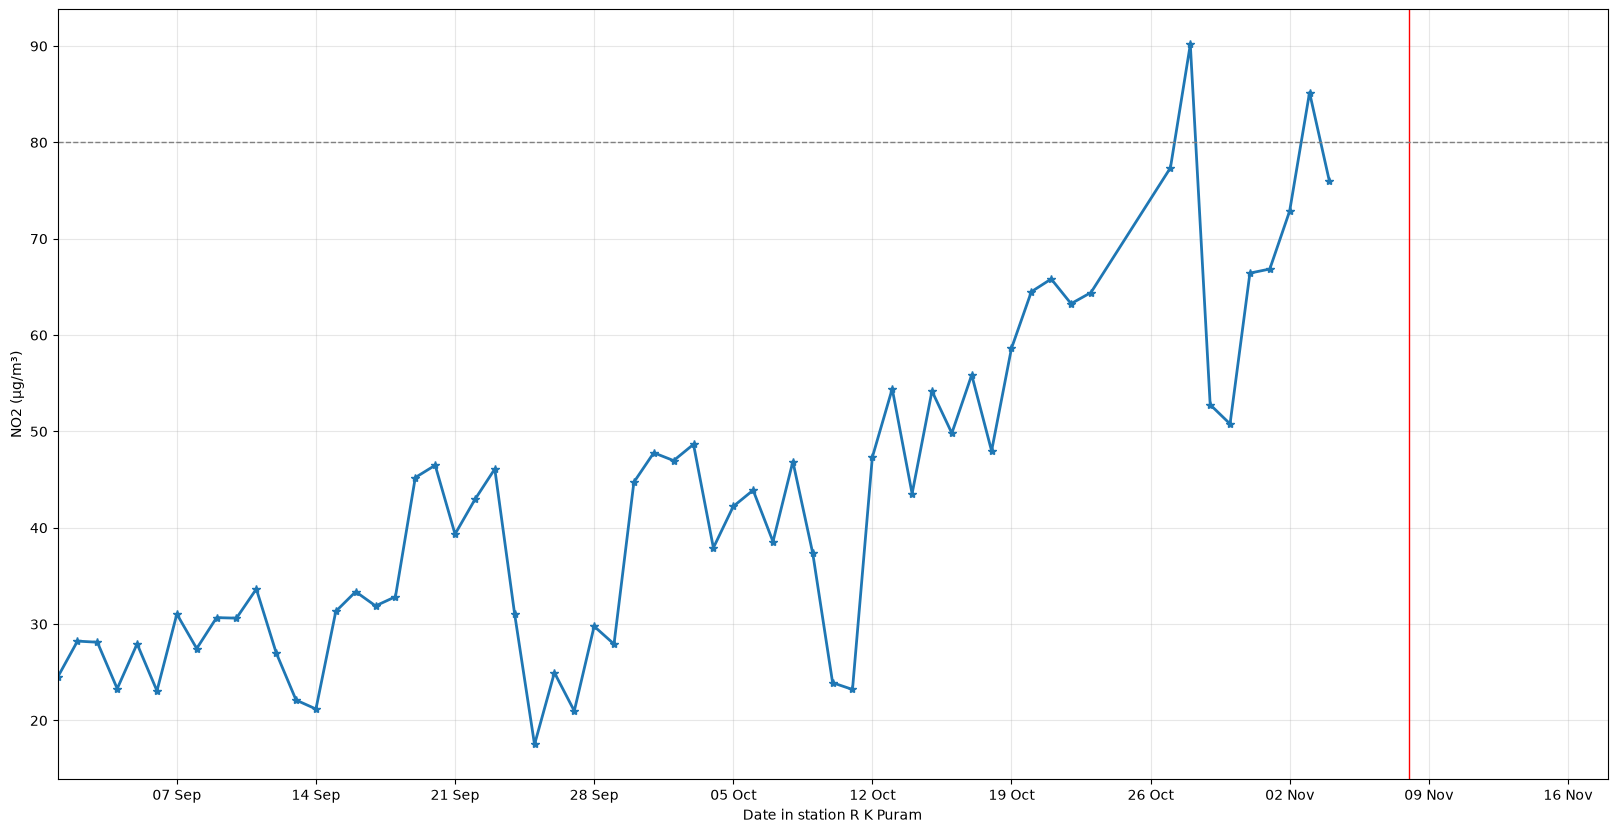

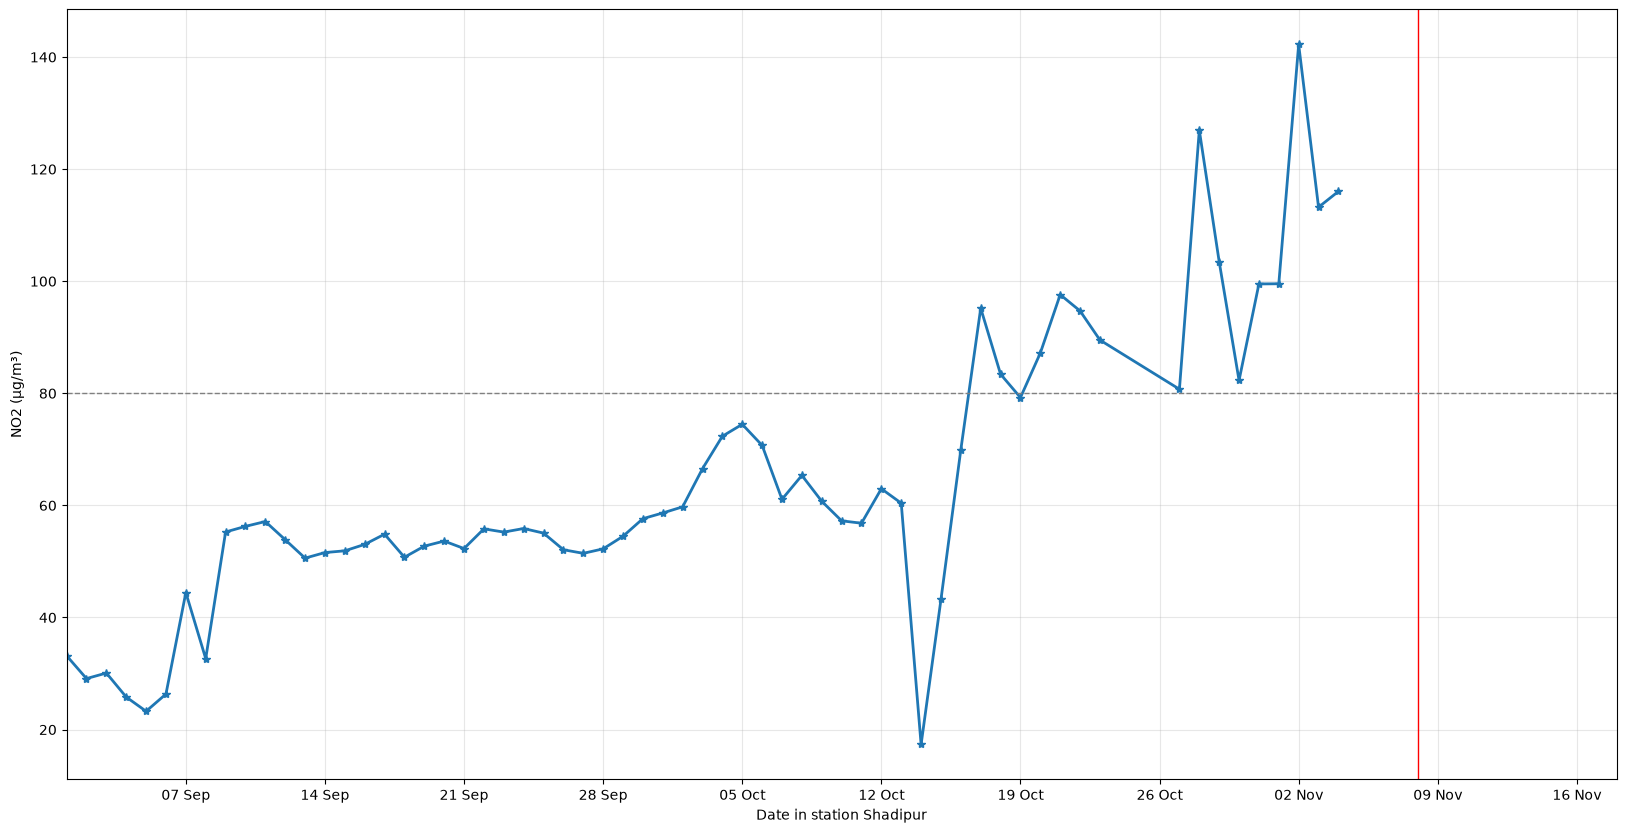

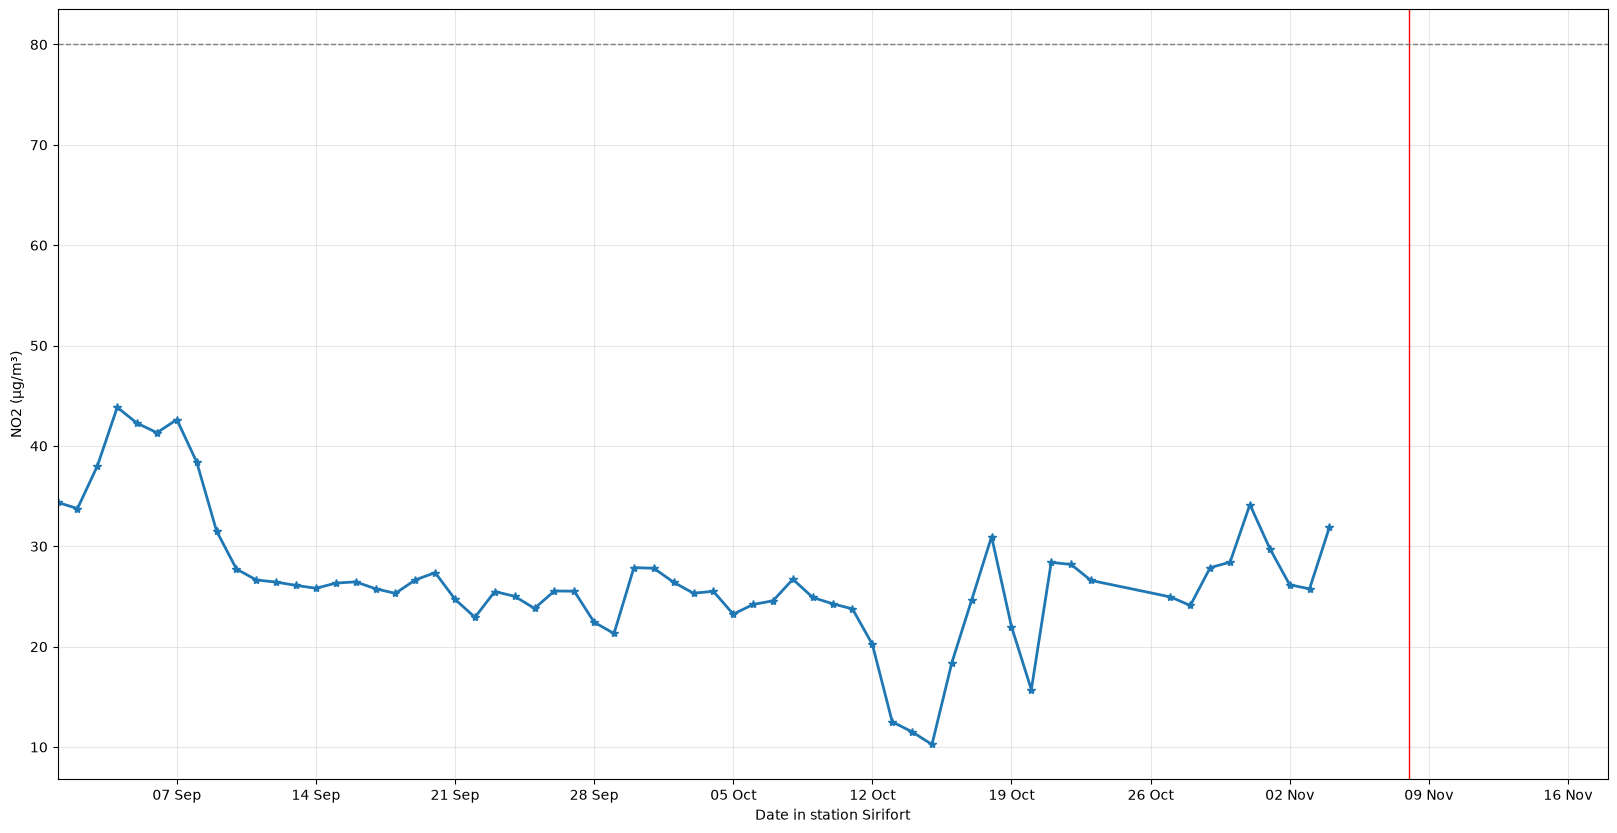

In [9]:
plot_all_data_different_plot(all_record_df, "no2")

## All stations, PM10 and NO2

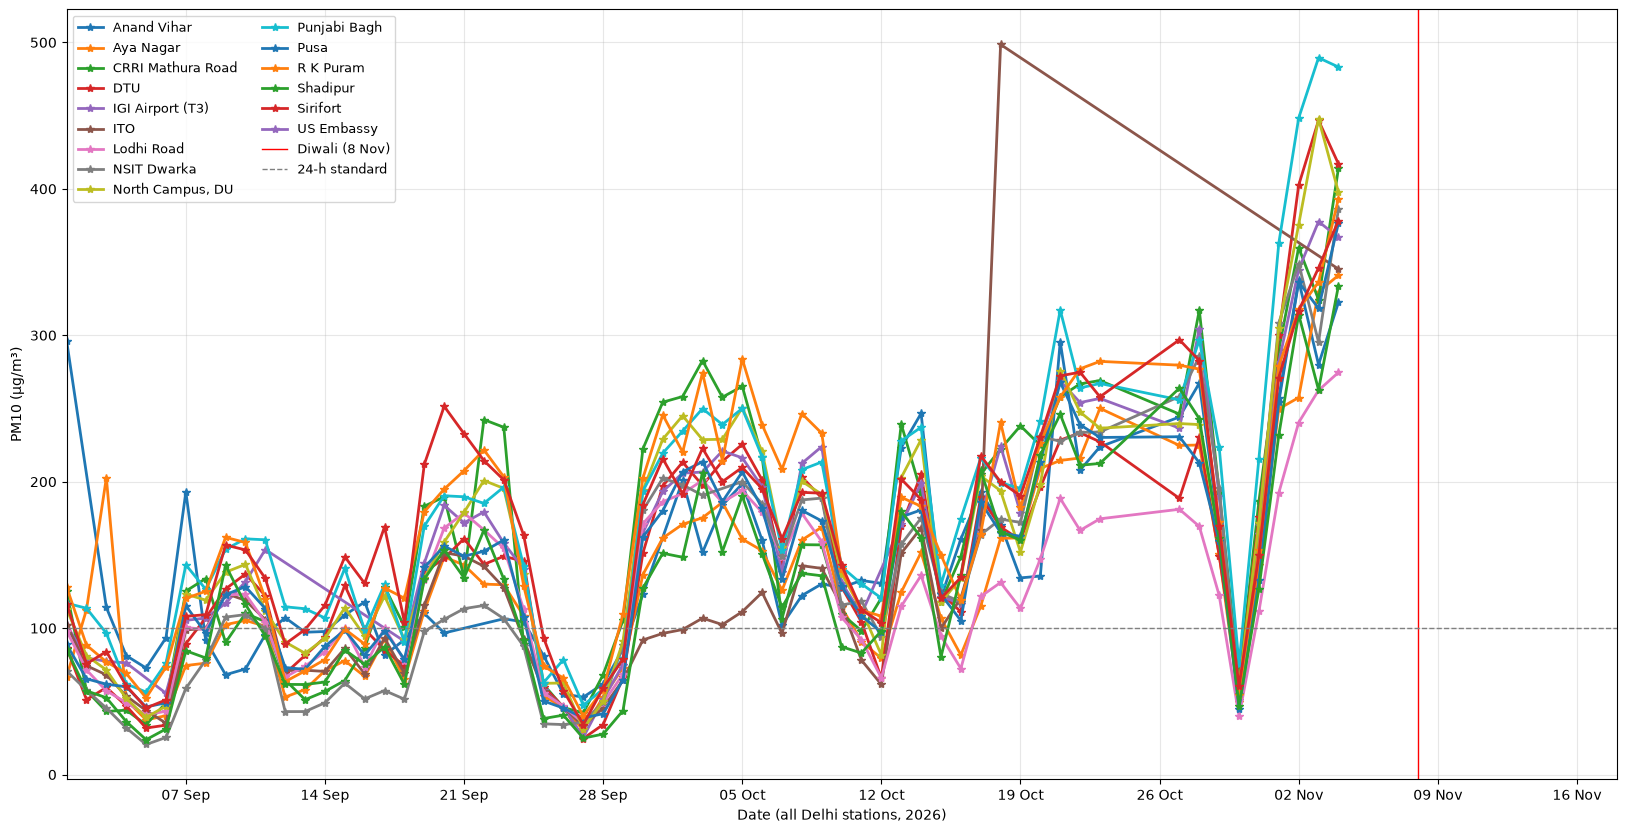

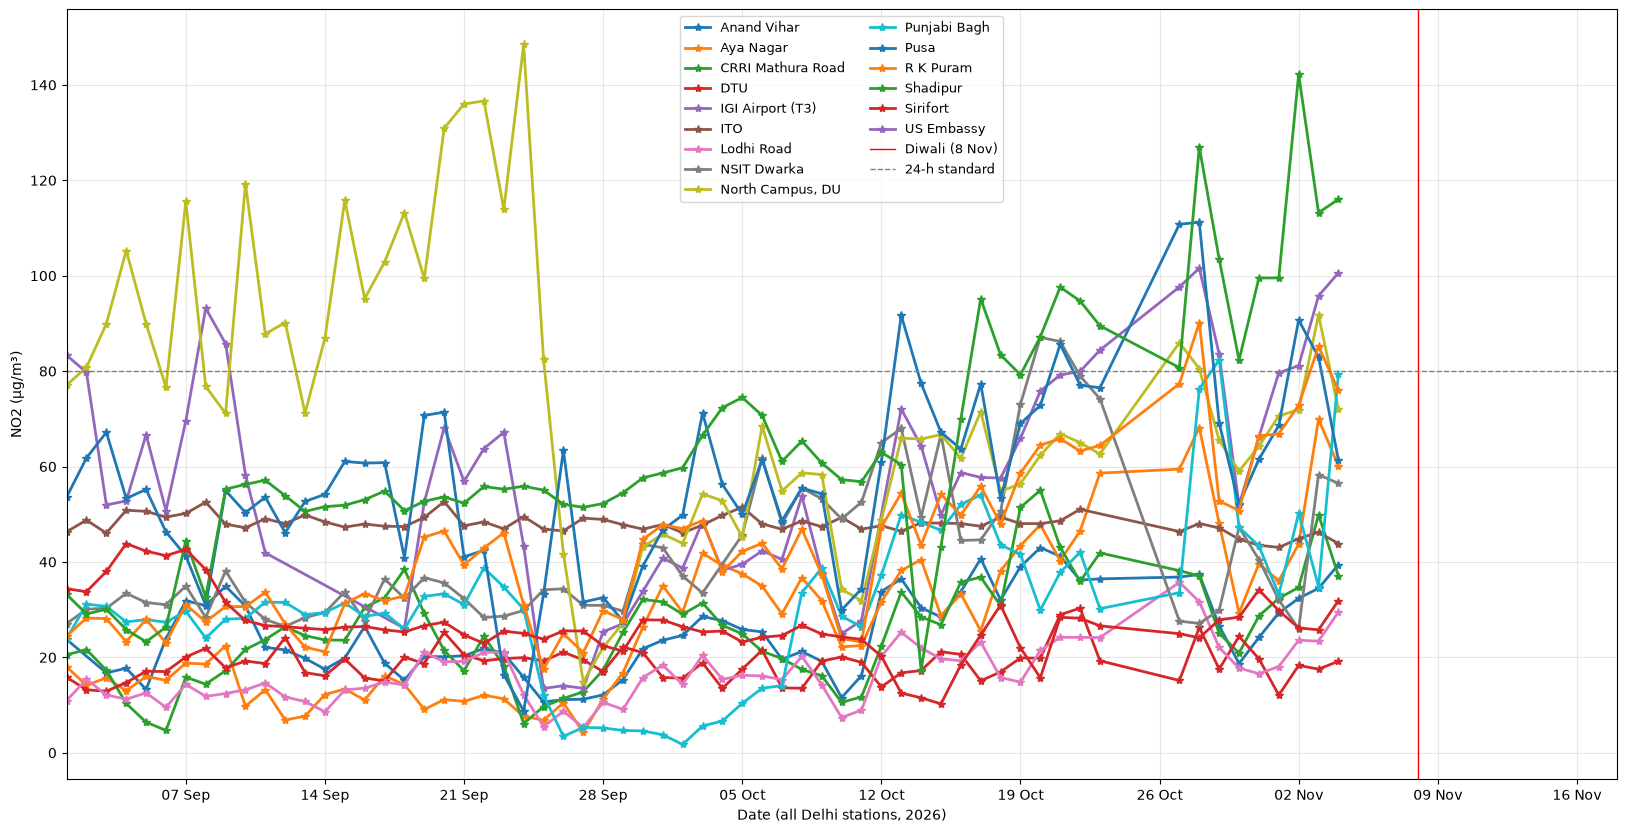

In [10]:
plot_all_data(all_record_df, "pm10")
plot_all_data(all_record_df, "no2")

## All record dataframe

In [11]:
all_record_df.to_csv("data/delhi_daily_2026.csv", index=False, float_format="%.1f")
all_record_df

parameter,station,date,no2,pm10,pm25
0,Anand Vihar,2026-09-01,23.748276,296.266667,56.181818
1,Anand Vihar,2026-09-03,16.741270,114.120000,47.836735
2,Anand Vihar,2026-09-04,17.720833,81.222222,19.418605
3,Anand Vihar,2026-09-05,13.267708,72.784091,1.000000
4,Anand Vihar,2026-09-06,23.902222,93.387097,15.419753
...,...,...,...,...,...
900,US Embassy,2026-10-31,NaN,NaN,87.428571
901,US Embassy,2026-11-01,NaN,NaN,164.250000
902,US Embassy,2026-11-02,NaN,NaN,184.000000
903,US Embassy,2026-11-03,NaN,NaN,232.782609
